# 🐧 Esercitazione 3 — Iperparametri, pruning, cross-validation ed ensemble

**new ALF – Tutorato** · Corso di Laurea in Informatica · AA 2026/27

Oggi vediamo **come si sceglie un albero** in scikit-learn: **iperparametri** e **pruning**, **cross-validation** e ricerca automatica con **`GridSearchCV`**. Poi guardiamo quanto cambia un albero da un campione all'altro, e come gli **ensemble** (random forest e boosting) sfruttano questa instabilità.

Useremo di nuovo il dataset **Palmer Penguins**: le misure di 344 pinguini di tre specie (Adelie, Chinstrap e Gentoo), raccolte tra il 2007 e il 2009 su tre isole dell'arcipelago Palmer, in Antartide.


> ### ⚠️ Prima di tutto: fai la tua copia
> Questo notebook è condiviso in **sola lettura**: puoi eseguirlo e modificarlo, ma le modifiche **non verranno salvate**.
> Vai su **File → Salva una copia in Drive**. Si aprirà una nuova scheda con la *tua* copia (la trovi poi su Google Drive, nella cartella *Colab Notebooks*): lavora lì.

### Come si usa questo notebook
- Ogni **cella** si esegue con **Shift + Invio** (o con il tasto ▶ a sinistra). Esegui le celle **in ordine**, dall'alto verso il basso.
- Le celle segnate con **✏️** sono esercizi: modifica il codice dove indicato. Sotto ogni esercizio c'è un blocco **💡 Soluzione** chiuso: prova prima da solo. Le celle successive funzionano anche se lasci l'esercizio in bianco.
- I box **🐍** spiegano le cose nuove di Python che incontriamo strada facendo.
- Le sezioni segnate con **⏩** sono approfondimenti.
- I box **📋** dicono quale problema stiamo risolvendo; **🤔** sono domande su cui riflettere, **📌** i concetti chiave.
- **🔒 / 🔓**: il test set resta chiuso finché non abbiamo scelto il modello, e si apre una volta sola.
- Se qualcosa si rompe: menu **Runtime → Riavvia sessione ed esegui tutto** (*Restart session and run all*).

In [1]:
#@title ⚙️ Setup: esegui questa cella per prima (crea il file con i dati)
# Questa cella scrive nel workspace di Colab il file "pinguini.csv". Puoi vederlo nel pannello 📁 a sinistra.
# Nota: il workspace di Colab si svuota quando la sessione termina,
# quindi questa cella va rieseguita ogni volta che riapri il notebook.
#
# Dati: Palmer Penguins (Gorman, Williams & Fraser, 2014), raccolti alla Palmer Station (Antartide)
# e distribuiti con licenza CC0 dal pacchetto palmerpenguins di A. Horst, A. Hill e K. Gorman.
# Nomi delle colonne e valori del sesso tradotti in italiano.

PINGUINI_CSV = """specie,isola,becco_lunghezza,becco_profondita,pinna,peso,sesso
Adelie,Torgersen,39.1,18.7,181,3750,maschio
Adelie,Torgersen,39.5,17.4,186,3800,femmina
Adelie,Torgersen,40.3,18,195,3250,femmina
Adelie,Torgersen,,,,,
Adelie,Torgersen,36.7,19.3,193,3450,femmina
Adelie,Torgersen,39.3,20.6,190,3650,maschio
Adelie,Torgersen,38.9,17.8,181,3625,femmina
Adelie,Torgersen,39.2,19.6,195,4675,maschio
Adelie,Torgersen,34.1,18.1,193,3475,
Adelie,Torgersen,42,20.2,190,4250,
Adelie,Torgersen,37.8,17.1,186,3300,
Adelie,Torgersen,37.8,17.3,180,3700,
Adelie,Torgersen,41.1,17.6,182,3200,femmina
Adelie,Torgersen,38.6,21.2,191,3800,maschio
Adelie,Torgersen,34.6,21.1,198,4400,maschio
Adelie,Torgersen,36.6,17.8,185,3700,femmina
Adelie,Torgersen,38.7,19,195,3450,femmina
Adelie,Torgersen,42.5,20.7,197,4500,maschio
Adelie,Torgersen,34.4,18.4,184,3325,femmina
Adelie,Torgersen,46,21.5,194,4200,maschio
Adelie,Biscoe,37.8,18.3,174,3400,femmina
Adelie,Biscoe,37.7,18.7,180,3600,maschio
Adelie,Biscoe,35.9,19.2,189,3800,femmina
Adelie,Biscoe,38.2,18.1,185,3950,maschio
Adelie,Biscoe,38.8,17.2,180,3800,maschio
Adelie,Biscoe,35.3,18.9,187,3800,femmina
Adelie,Biscoe,40.6,18.6,183,3550,maschio
Adelie,Biscoe,40.5,17.9,187,3200,femmina
Adelie,Biscoe,37.9,18.6,172,3150,femmina
Adelie,Biscoe,40.5,18.9,180,3950,maschio
Adelie,Dream,39.5,16.7,178,3250,femmina
Adelie,Dream,37.2,18.1,178,3900,maschio
Adelie,Dream,39.5,17.8,188,3300,femmina
Adelie,Dream,40.9,18.9,184,3900,maschio
Adelie,Dream,36.4,17,195,3325,femmina
Adelie,Dream,39.2,21.1,196,4150,maschio
Adelie,Dream,38.8,20,190,3950,maschio
Adelie,Dream,42.2,18.5,180,3550,femmina
Adelie,Dream,37.6,19.3,181,3300,femmina
Adelie,Dream,39.8,19.1,184,4650,maschio
Adelie,Dream,36.5,18,182,3150,femmina
Adelie,Dream,40.8,18.4,195,3900,maschio
Adelie,Dream,36,18.5,186,3100,femmina
Adelie,Dream,44.1,19.7,196,4400,maschio
Adelie,Dream,37,16.9,185,3000,femmina
Adelie,Dream,39.6,18.8,190,4600,maschio
Adelie,Dream,41.1,19,182,3425,maschio
Adelie,Dream,37.5,18.9,179,2975,
Adelie,Dream,36,17.9,190,3450,femmina
Adelie,Dream,42.3,21.2,191,4150,maschio
Adelie,Biscoe,39.6,17.7,186,3500,femmina
Adelie,Biscoe,40.1,18.9,188,4300,maschio
Adelie,Biscoe,35,17.9,190,3450,femmina
Adelie,Biscoe,42,19.5,200,4050,maschio
Adelie,Biscoe,34.5,18.1,187,2900,femmina
Adelie,Biscoe,41.4,18.6,191,3700,maschio
Adelie,Biscoe,39,17.5,186,3550,femmina
Adelie,Biscoe,40.6,18.8,193,3800,maschio
Adelie,Biscoe,36.5,16.6,181,2850,femmina
Adelie,Biscoe,37.6,19.1,194,3750,maschio
Adelie,Biscoe,35.7,16.9,185,3150,femmina
Adelie,Biscoe,41.3,21.1,195,4400,maschio
Adelie,Biscoe,37.6,17,185,3600,femmina
Adelie,Biscoe,41.1,18.2,192,4050,maschio
Adelie,Biscoe,36.4,17.1,184,2850,femmina
Adelie,Biscoe,41.6,18,192,3950,maschio
Adelie,Biscoe,35.5,16.2,195,3350,femmina
Adelie,Biscoe,41.1,19.1,188,4100,maschio
Adelie,Torgersen,35.9,16.6,190,3050,femmina
Adelie,Torgersen,41.8,19.4,198,4450,maschio
Adelie,Torgersen,33.5,19,190,3600,femmina
Adelie,Torgersen,39.7,18.4,190,3900,maschio
Adelie,Torgersen,39.6,17.2,196,3550,femmina
Adelie,Torgersen,45.8,18.9,197,4150,maschio
Adelie,Torgersen,35.5,17.5,190,3700,femmina
Adelie,Torgersen,42.8,18.5,195,4250,maschio
Adelie,Torgersen,40.9,16.8,191,3700,femmina
Adelie,Torgersen,37.2,19.4,184,3900,maschio
Adelie,Torgersen,36.2,16.1,187,3550,femmina
Adelie,Torgersen,42.1,19.1,195,4000,maschio
Adelie,Torgersen,34.6,17.2,189,3200,femmina
Adelie,Torgersen,42.9,17.6,196,4700,maschio
Adelie,Torgersen,36.7,18.8,187,3800,femmina
Adelie,Torgersen,35.1,19.4,193,4200,maschio
Adelie,Dream,37.3,17.8,191,3350,femmina
Adelie,Dream,41.3,20.3,194,3550,maschio
Adelie,Dream,36.3,19.5,190,3800,maschio
Adelie,Dream,36.9,18.6,189,3500,femmina
Adelie,Dream,38.3,19.2,189,3950,maschio
Adelie,Dream,38.9,18.8,190,3600,femmina
Adelie,Dream,35.7,18,202,3550,femmina
Adelie,Dream,41.1,18.1,205,4300,maschio
Adelie,Dream,34,17.1,185,3400,femmina
Adelie,Dream,39.6,18.1,186,4450,maschio
Adelie,Dream,36.2,17.3,187,3300,femmina
Adelie,Dream,40.8,18.9,208,4300,maschio
Adelie,Dream,38.1,18.6,190,3700,femmina
Adelie,Dream,40.3,18.5,196,4350,maschio
Adelie,Dream,33.1,16.1,178,2900,femmina
Adelie,Dream,43.2,18.5,192,4100,maschio
Adelie,Biscoe,35,17.9,192,3725,femmina
Adelie,Biscoe,41,20,203,4725,maschio
Adelie,Biscoe,37.7,16,183,3075,femmina
Adelie,Biscoe,37.8,20,190,4250,maschio
Adelie,Biscoe,37.9,18.6,193,2925,femmina
Adelie,Biscoe,39.7,18.9,184,3550,maschio
Adelie,Biscoe,38.6,17.2,199,3750,femmina
Adelie,Biscoe,38.2,20,190,3900,maschio
Adelie,Biscoe,38.1,17,181,3175,femmina
Adelie,Biscoe,43.2,19,197,4775,maschio
Adelie,Biscoe,38.1,16.5,198,3825,femmina
Adelie,Biscoe,45.6,20.3,191,4600,maschio
Adelie,Biscoe,39.7,17.7,193,3200,femmina
Adelie,Biscoe,42.2,19.5,197,4275,maschio
Adelie,Biscoe,39.6,20.7,191,3900,femmina
Adelie,Biscoe,42.7,18.3,196,4075,maschio
Adelie,Torgersen,38.6,17,188,2900,femmina
Adelie,Torgersen,37.3,20.5,199,3775,maschio
Adelie,Torgersen,35.7,17,189,3350,femmina
Adelie,Torgersen,41.1,18.6,189,3325,maschio
Adelie,Torgersen,36.2,17.2,187,3150,femmina
Adelie,Torgersen,37.7,19.8,198,3500,maschio
Adelie,Torgersen,40.2,17,176,3450,femmina
Adelie,Torgersen,41.4,18.5,202,3875,maschio
Adelie,Torgersen,35.2,15.9,186,3050,femmina
Adelie,Torgersen,40.6,19,199,4000,maschio
Adelie,Torgersen,38.8,17.6,191,3275,femmina
Adelie,Torgersen,41.5,18.3,195,4300,maschio
Adelie,Torgersen,39,17.1,191,3050,femmina
Adelie,Torgersen,44.1,18,210,4000,maschio
Adelie,Torgersen,38.5,17.9,190,3325,femmina
Adelie,Torgersen,43.1,19.2,197,3500,maschio
Adelie,Dream,36.8,18.5,193,3500,femmina
Adelie,Dream,37.5,18.5,199,4475,maschio
Adelie,Dream,38.1,17.6,187,3425,femmina
Adelie,Dream,41.1,17.5,190,3900,maschio
Adelie,Dream,35.6,17.5,191,3175,femmina
Adelie,Dream,40.2,20.1,200,3975,maschio
Adelie,Dream,37,16.5,185,3400,femmina
Adelie,Dream,39.7,17.9,193,4250,maschio
Adelie,Dream,40.2,17.1,193,3400,femmina
Adelie,Dream,40.6,17.2,187,3475,maschio
Adelie,Dream,32.1,15.5,188,3050,femmina
Adelie,Dream,40.7,17,190,3725,maschio
Adelie,Dream,37.3,16.8,192,3000,femmina
Adelie,Dream,39,18.7,185,3650,maschio
Adelie,Dream,39.2,18.6,190,4250,maschio
Adelie,Dream,36.6,18.4,184,3475,femmina
Adelie,Dream,36,17.8,195,3450,femmina
Adelie,Dream,37.8,18.1,193,3750,maschio
Adelie,Dream,36,17.1,187,3700,femmina
Adelie,Dream,41.5,18.5,201,4000,maschio
Chinstrap,Dream,46.5,17.9,192,3500,femmina
Chinstrap,Dream,50,19.5,196,3900,maschio
Chinstrap,Dream,51.3,19.2,193,3650,maschio
Chinstrap,Dream,45.4,18.7,188,3525,femmina
Chinstrap,Dream,52.7,19.8,197,3725,maschio
Chinstrap,Dream,45.2,17.8,198,3950,femmina
Chinstrap,Dream,46.1,18.2,178,3250,femmina
Chinstrap,Dream,51.3,18.2,197,3750,maschio
Chinstrap,Dream,46,18.9,195,4150,femmina
Chinstrap,Dream,51.3,19.9,198,3700,maschio
Chinstrap,Dream,46.6,17.8,193,3800,femmina
Chinstrap,Dream,51.7,20.3,194,3775,maschio
Chinstrap,Dream,47,17.3,185,3700,femmina
Chinstrap,Dream,52,18.1,201,4050,maschio
Chinstrap,Dream,45.9,17.1,190,3575,femmina
Chinstrap,Dream,50.5,19.6,201,4050,maschio
Chinstrap,Dream,50.3,20,197,3300,maschio
Chinstrap,Dream,58,17.8,181,3700,femmina
Chinstrap,Dream,46.4,18.6,190,3450,femmina
Chinstrap,Dream,49.2,18.2,195,4400,maschio
Chinstrap,Dream,42.4,17.3,181,3600,femmina
Chinstrap,Dream,48.5,17.5,191,3400,maschio
Chinstrap,Dream,43.2,16.6,187,2900,femmina
Chinstrap,Dream,50.6,19.4,193,3800,maschio
Chinstrap,Dream,46.7,17.9,195,3300,femmina
Chinstrap,Dream,52,19,197,4150,maschio
Chinstrap,Dream,50.5,18.4,200,3400,femmina
Chinstrap,Dream,49.5,19,200,3800,maschio
Chinstrap,Dream,46.4,17.8,191,3700,femmina
Chinstrap,Dream,52.8,20,205,4550,maschio
Chinstrap,Dream,40.9,16.6,187,3200,femmina
Chinstrap,Dream,54.2,20.8,201,4300,maschio
Chinstrap,Dream,42.5,16.7,187,3350,femmina
Chinstrap,Dream,51,18.8,203,4100,maschio
Chinstrap,Dream,49.7,18.6,195,3600,maschio
Chinstrap,Dream,47.5,16.8,199,3900,femmina
Chinstrap,Dream,47.6,18.3,195,3850,femmina
Chinstrap,Dream,52,20.7,210,4800,maschio
Chinstrap,Dream,46.9,16.6,192,2700,femmina
Chinstrap,Dream,53.5,19.9,205,4500,maschio
Chinstrap,Dream,49,19.5,210,3950,maschio
Chinstrap,Dream,46.2,17.5,187,3650,femmina
Chinstrap,Dream,50.9,19.1,196,3550,maschio
Chinstrap,Dream,45.5,17,196,3500,femmina
Chinstrap,Dream,50.9,17.9,196,3675,femmina
Chinstrap,Dream,50.8,18.5,201,4450,maschio
Chinstrap,Dream,50.1,17.9,190,3400,femmina
Chinstrap,Dream,49,19.6,212,4300,maschio
Chinstrap,Dream,51.5,18.7,187,3250,maschio
Chinstrap,Dream,49.8,17.3,198,3675,femmina
Chinstrap,Dream,48.1,16.4,199,3325,femmina
Chinstrap,Dream,51.4,19,201,3950,maschio
Chinstrap,Dream,45.7,17.3,193,3600,femmina
Chinstrap,Dream,50.7,19.7,203,4050,maschio
Chinstrap,Dream,42.5,17.3,187,3350,femmina
Chinstrap,Dream,52.2,18.8,197,3450,maschio
Chinstrap,Dream,45.2,16.6,191,3250,femmina
Chinstrap,Dream,49.3,19.9,203,4050,maschio
Chinstrap,Dream,50.2,18.8,202,3800,maschio
Chinstrap,Dream,45.6,19.4,194,3525,femmina
Chinstrap,Dream,51.9,19.5,206,3950,maschio
Chinstrap,Dream,46.8,16.5,189,3650,femmina
Chinstrap,Dream,45.7,17,195,3650,femmina
Chinstrap,Dream,55.8,19.8,207,4000,maschio
Chinstrap,Dream,43.5,18.1,202,3400,femmina
Chinstrap,Dream,49.6,18.2,193,3775,maschio
Chinstrap,Dream,50.8,19,210,4100,maschio
Chinstrap,Dream,50.2,18.7,198,3775,femmina
Gentoo,Biscoe,46.1,13.2,211,4500,femmina
Gentoo,Biscoe,50,16.3,230,5700,maschio
Gentoo,Biscoe,48.7,14.1,210,4450,femmina
Gentoo,Biscoe,50,15.2,218,5700,maschio
Gentoo,Biscoe,47.6,14.5,215,5400,maschio
Gentoo,Biscoe,46.5,13.5,210,4550,femmina
Gentoo,Biscoe,45.4,14.6,211,4800,femmina
Gentoo,Biscoe,46.7,15.3,219,5200,maschio
Gentoo,Biscoe,43.3,13.4,209,4400,femmina
Gentoo,Biscoe,46.8,15.4,215,5150,maschio
Gentoo,Biscoe,40.9,13.7,214,4650,femmina
Gentoo,Biscoe,49,16.1,216,5550,maschio
Gentoo,Biscoe,45.5,13.7,214,4650,femmina
Gentoo,Biscoe,48.4,14.6,213,5850,maschio
Gentoo,Biscoe,45.8,14.6,210,4200,femmina
Gentoo,Biscoe,49.3,15.7,217,5850,maschio
Gentoo,Biscoe,42,13.5,210,4150,femmina
Gentoo,Biscoe,49.2,15.2,221,6300,maschio
Gentoo,Biscoe,46.2,14.5,209,4800,femmina
Gentoo,Biscoe,48.7,15.1,222,5350,maschio
Gentoo,Biscoe,50.2,14.3,218,5700,maschio
Gentoo,Biscoe,45.1,14.5,215,5000,femmina
Gentoo,Biscoe,46.5,14.5,213,4400,femmina
Gentoo,Biscoe,46.3,15.8,215,5050,maschio
Gentoo,Biscoe,42.9,13.1,215,5000,femmina
Gentoo,Biscoe,46.1,15.1,215,5100,maschio
Gentoo,Biscoe,44.5,14.3,216,4100,
Gentoo,Biscoe,47.8,15,215,5650,maschio
Gentoo,Biscoe,48.2,14.3,210,4600,femmina
Gentoo,Biscoe,50,15.3,220,5550,maschio
Gentoo,Biscoe,47.3,15.3,222,5250,maschio
Gentoo,Biscoe,42.8,14.2,209,4700,femmina
Gentoo,Biscoe,45.1,14.5,207,5050,femmina
Gentoo,Biscoe,59.6,17,230,6050,maschio
Gentoo,Biscoe,49.1,14.8,220,5150,femmina
Gentoo,Biscoe,48.4,16.3,220,5400,maschio
Gentoo,Biscoe,42.6,13.7,213,4950,femmina
Gentoo,Biscoe,44.4,17.3,219,5250,maschio
Gentoo,Biscoe,44,13.6,208,4350,femmina
Gentoo,Biscoe,48.7,15.7,208,5350,maschio
Gentoo,Biscoe,42.7,13.7,208,3950,femmina
Gentoo,Biscoe,49.6,16,225,5700,maschio
Gentoo,Biscoe,45.3,13.7,210,4300,femmina
Gentoo,Biscoe,49.6,15,216,4750,maschio
Gentoo,Biscoe,50.5,15.9,222,5550,maschio
Gentoo,Biscoe,43.6,13.9,217,4900,femmina
Gentoo,Biscoe,45.5,13.9,210,4200,femmina
Gentoo,Biscoe,50.5,15.9,225,5400,maschio
Gentoo,Biscoe,44.9,13.3,213,5100,femmina
Gentoo,Biscoe,45.2,15.8,215,5300,maschio
Gentoo,Biscoe,46.6,14.2,210,4850,femmina
Gentoo,Biscoe,48.5,14.1,220,5300,maschio
Gentoo,Biscoe,45.1,14.4,210,4400,femmina
Gentoo,Biscoe,50.1,15,225,5000,maschio
Gentoo,Biscoe,46.5,14.4,217,4900,femmina
Gentoo,Biscoe,45,15.4,220,5050,maschio
Gentoo,Biscoe,43.8,13.9,208,4300,femmina
Gentoo,Biscoe,45.5,15,220,5000,maschio
Gentoo,Biscoe,43.2,14.5,208,4450,femmina
Gentoo,Biscoe,50.4,15.3,224,5550,maschio
Gentoo,Biscoe,45.3,13.8,208,4200,femmina
Gentoo,Biscoe,46.2,14.9,221,5300,maschio
Gentoo,Biscoe,45.7,13.9,214,4400,femmina
Gentoo,Biscoe,54.3,15.7,231,5650,maschio
Gentoo,Biscoe,45.8,14.2,219,4700,femmina
Gentoo,Biscoe,49.8,16.8,230,5700,maschio
Gentoo,Biscoe,46.2,14.4,214,4650,
Gentoo,Biscoe,49.5,16.2,229,5800,maschio
Gentoo,Biscoe,43.5,14.2,220,4700,femmina
Gentoo,Biscoe,50.7,15,223,5550,maschio
Gentoo,Biscoe,47.7,15,216,4750,femmina
Gentoo,Biscoe,46.4,15.6,221,5000,maschio
Gentoo,Biscoe,48.2,15.6,221,5100,maschio
Gentoo,Biscoe,46.5,14.8,217,5200,femmina
Gentoo,Biscoe,46.4,15,216,4700,femmina
Gentoo,Biscoe,48.6,16,230,5800,maschio
Gentoo,Biscoe,47.5,14.2,209,4600,femmina
Gentoo,Biscoe,51.1,16.3,220,6000,maschio
Gentoo,Biscoe,45.2,13.8,215,4750,femmina
Gentoo,Biscoe,45.2,16.4,223,5950,maschio
Gentoo,Biscoe,49.1,14.5,212,4625,femmina
Gentoo,Biscoe,52.5,15.6,221,5450,maschio
Gentoo,Biscoe,47.4,14.6,212,4725,femmina
Gentoo,Biscoe,50,15.9,224,5350,maschio
Gentoo,Biscoe,44.9,13.8,212,4750,femmina
Gentoo,Biscoe,50.8,17.3,228,5600,maschio
Gentoo,Biscoe,43.4,14.4,218,4600,femmina
Gentoo,Biscoe,51.3,14.2,218,5300,maschio
Gentoo,Biscoe,47.5,14,212,4875,femmina
Gentoo,Biscoe,52.1,17,230,5550,maschio
Gentoo,Biscoe,47.5,15,218,4950,femmina
Gentoo,Biscoe,52.2,17.1,228,5400,maschio
Gentoo,Biscoe,45.5,14.5,212,4750,femmina
Gentoo,Biscoe,49.5,16.1,224,5650,maschio
Gentoo,Biscoe,44.5,14.7,214,4850,femmina
Gentoo,Biscoe,50.8,15.7,226,5200,maschio
Gentoo,Biscoe,49.4,15.8,216,4925,maschio
Gentoo,Biscoe,46.9,14.6,222,4875,femmina
Gentoo,Biscoe,48.4,14.4,203,4625,femmina
Gentoo,Biscoe,51.1,16.5,225,5250,maschio
Gentoo,Biscoe,48.5,15,219,4850,femmina
Gentoo,Biscoe,55.9,17,228,5600,maschio
Gentoo,Biscoe,47.2,15.5,215,4975,femmina
Gentoo,Biscoe,49.1,15,228,5500,maschio
Gentoo,Biscoe,47.3,13.8,216,4725,
Gentoo,Biscoe,46.8,16.1,215,5500,maschio
Gentoo,Biscoe,41.7,14.7,210,4700,femmina
Gentoo,Biscoe,53.4,15.8,219,5500,maschio
Gentoo,Biscoe,43.3,14,208,4575,femmina
Gentoo,Biscoe,48.1,15.1,209,5500,maschio
Gentoo,Biscoe,50.5,15.2,216,5000,femmina
Gentoo,Biscoe,49.8,15.9,229,5950,maschio
Gentoo,Biscoe,43.5,15.2,213,4650,femmina
Gentoo,Biscoe,51.5,16.3,230,5500,maschio
Gentoo,Biscoe,46.2,14.1,217,4375,femmina
Gentoo,Biscoe,55.1,16,230,5850,maschio
Gentoo,Biscoe,44.5,15.7,217,4875,
Gentoo,Biscoe,48.8,16.2,222,6000,maschio
Gentoo,Biscoe,47.2,13.7,214,4925,femmina
Gentoo,Biscoe,,,,,
Gentoo,Biscoe,46.8,14.3,215,4850,femmina
Gentoo,Biscoe,50.4,15.7,222,5750,maschio
Gentoo,Biscoe,45.2,14.8,212,5200,femmina
Gentoo,Biscoe,49.9,16.1,213,5400,maschio
"""

with open("pinguini.csv", "w", encoding="utf-8") as f:
    f.write(PINGUINI_CSV)

print("✅ File pinguini.csv creato!")

✅ File pinguini.csv creato!


In [2]:
#@title 🛠️ Funzioni di supporto per i grafici (esegui la cella, non serve leggerla)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Un colore fisso per ogni classe, così lo stesso pinguino ha sempre lo stesso colore
COLORI = {"Adelie": "#FF8C00", "Chinstrap": "#A034F0", "Gentoo": "#159090",
          "femmina": "#D9534F", "maschio": "#2C7FB8"}

def predici(modello, X):
    """Predizioni per X: funziona sia con un modello sklearn (che ha .predict)
    sia con una funzione scritta da noi che riceve un DataFrame."""
    if hasattr(modello, "predict"):
        return np.asarray(modello.predict(X))
    return np.asarray(modello(X))

def _griglia(X, passi=300):
    c1, c2 = X.columns
    m1 = (X[c1].max() - X[c1].min()) * 0.05
    m2 = (X[c2].max() - X[c2].min()) * 0.05
    xx, yy = np.meshgrid(np.linspace(X[c1].min() - m1, X[c1].max() + m1, passi),
                         np.linspace(X[c2].min() - m2, X[c2].max() + m2, passi))
    return xx, yy, pd.DataFrame({c1: xx.ravel(), c2: yy.ravel()})

def mostra_punti(X, y, titolo="", ax=None):
    """Scatter plot di due feature, un colore per classe."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    c1, c2 = X.columns
    for classe in sorted(pd.unique(np.asarray(y))):
        sel = np.asarray(y) == classe
        ax.scatter(X[c1][sel], X[c2][sel], c=COLORI.get(classe, "gray"), label=classe,
                   edgecolors="k", linewidths=0.5, s=35)
    ax.set_xlabel(c1); ax.set_ylabel(c2); ax.set_title(titolo)
    ax.legend(fontsize=8); ax.grid(alpha=0.3)
    if nuovo:
        plt.show()

def disegna_frontiera(modello, X, y, titolo="", ax=None):
    """Colora il piano secondo la classe predetta dal modello (frontiera decisionale)."""
    nuovo = ax is None
    if nuovo:
        fig, ax = plt.subplots(figsize=(7, 5))
    xx, yy, griglia = _griglia(X)
    pred = predici(modello, griglia)
    classi = sorted(set(pd.unique(pred)) | set(pd.unique(np.asarray(y))))
    indice = {c: i for i, c in enumerate(classi)}
    z = np.array([indice[p] for p in pred]).reshape(xx.shape)
    cmap = ListedColormap([COLORI.get(c, "gray") for c in classi])
    ax.contourf(xx, yy, z, alpha=0.25, cmap=cmap, levels=np.arange(len(classi) + 1) - 0.5)
    mostra_punti(X, y, titolo, ax=ax)
    if nuovo:
        plt.show()

print("✅ Funzioni pronte: mostra_punti, disegna_frontiera")

✅ Funzioni pronte: mostra_punti, disegna_frontiera


### 🔁 Dall'Esercitazione 2 ci portiamo dietro
- Ogni modello di scikit-learn si usa allo stesso modo: lo **creo** scegliendo gli iperparametri, lo **addestro** con `.fit(X, y)`, lo **uso** con `.predict(X)`.
- I dati si dividono in **training set** (per addestrare) e **test set** (per valutare alla fine), con `train_test_split`.
- Un albero senza limiti va benissimo sul training e peggio sul test: è l'**overfitting**. Limitare `max_depth` lo riduce.
- Per **scegliere** un iperparametro non si può guardare il test set: serve un insieme di **validazione** separato. Oggi vediamo come si fa.

---
# Parte 1 — Il problema e il primo albero

Usiamo gli stessi pinguini dell'Esercitazione 2. Questa volta però non buttiamo via tutte le righe incomplete:
- i **2 pinguini** senza nessuna misura vengono eliminati;
- i **9 pinguini** che hanno tutte le misure ma **non il sesso** li teniamo da parte: alla fine proveremo a stimarne il sesso.

> 📋 **Il problema: è maschio o femmina?**
> - **Dati:** i 333 pinguini con il sesso registrato (i 9 senza sesso restano da parte)
> - **Target `y`:** `sesso`: maschio o femmina
> - **Feature `X`:** `becco_lunghezza` e `becco_profondita` (con due feature possiamo disegnare la frontiera; nella Parte 6 le useremo tutte)
> - **Tipo di problema:** **classificazione binaria**
> - **Come lo valutiamo:** accuracy, stimata con la cross-validation sul training set; il test set solo alla fine

Pinguini completi: 333 | senza sesso: 9
Training: 233 | test: 100


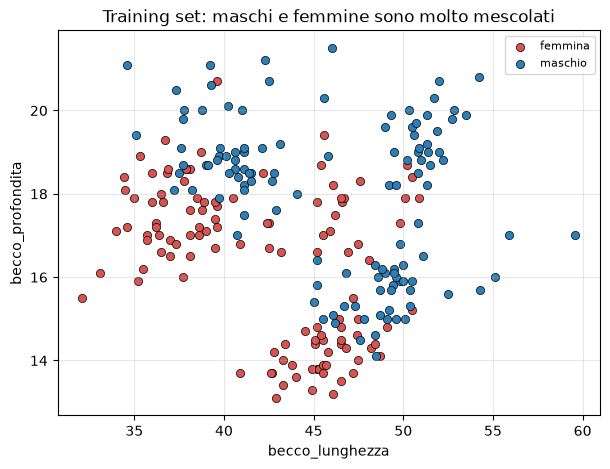

In [3]:
from sklearn.model_selection import train_test_split

pinguini = pd.read_csv("pinguini.csv")
senza_misure = pinguini["peso"].isna()                       # colonna di True/False
senza_sesso = pinguini["sesso"].isna() & ~senza_misure       # & = "AND" ; ~ = "NOT"

sesso_mancante = pinguini[senza_sesso]     # i 9 pinguini di cui non conosciamo il sesso
df = pinguini.dropna()                     # tutti i pinguini completi

X = df[["becco_lunghezza", "becco_profondita"]]
y = df["sesso"]

# stratify=y: training e test con la stessa proporzione di maschi e femmine
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

print("Pinguini completi:", len(df), "| senza sesso:", len(sesso_mancante))
print("Training:", len(X_train), "| test:", len(X_test))
mostra_punti(X_train, y_train, "Training set: maschi e femmine sono molto mescolati")

🔒 **Da qui in avanti il test set resta chiuso.** Lo apriremo una volta sola, alla fine della Parte 4, quando avremo scelto l'albero.

Cominciamo con un albero senza limiti, guardando solo il training set:

Profondità: 11 | foglie: 47
Accuracy sul training set: 1.00


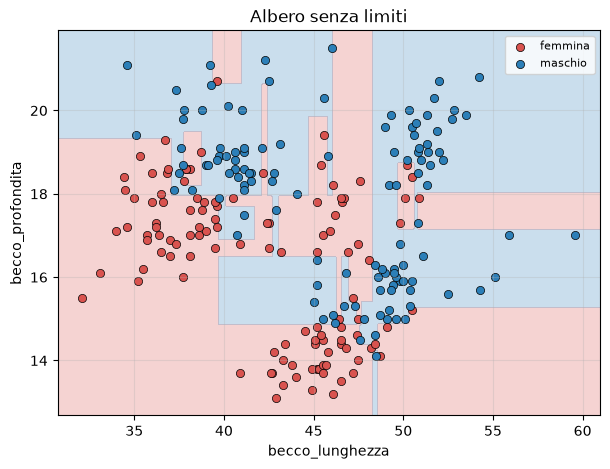

In [4]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

albero_libero = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
print("Profondità:", albero_libero.get_depth(), "| foglie:", albero_libero.get_n_leaves())
print(f"Accuracy sul training set: {accuracy_score(y_train, albero_libero.predict(X_train)):.2f}")
disegna_frontiera(albero_libero, X_train, y_train, "Albero senza limiti")

Accuracy di training **1.00**, con una frontiera piena di **isolette** costruite attorno a singoli pinguini: l'albero ha imparato a memoria il training set. Quanto andrà su pinguini nuovi non lo sappiamo ancora, e non possiamo chiederlo al test set. Prima vediamo quali "freni" possiamo mettere all'albero.

---
# Parte 2 — Gli iperparametri dell'albero: cosa cambiano

### 2.1 Cinque modi per fermare un albero
Oltre a `max_depth`, `DecisionTreeClassifier` ha altri iperparametri che limitano la crescita: `min_samples_leaf` (pinguini minimi in ogni foglia), `max_leaf_nodes` (foglie massime), `min_impurity_decrease` (divide un nodo solo se l'impurità scende almeno di tanto) e `ccp_alpha` (il pruning, vedi 2.2). Vediamoli all'opera.

> 🐍 `DecisionTreeClassifier(**parametri)`: i due asterischi "spacchettano" un dizionario in argomenti. Se `parametri = {"max_depth": 3}`, la chiamata equivale a `DecisionTreeClassifier(max_depth=3)`. Ci servirà per provare tante configurazioni con lo stesso codice.

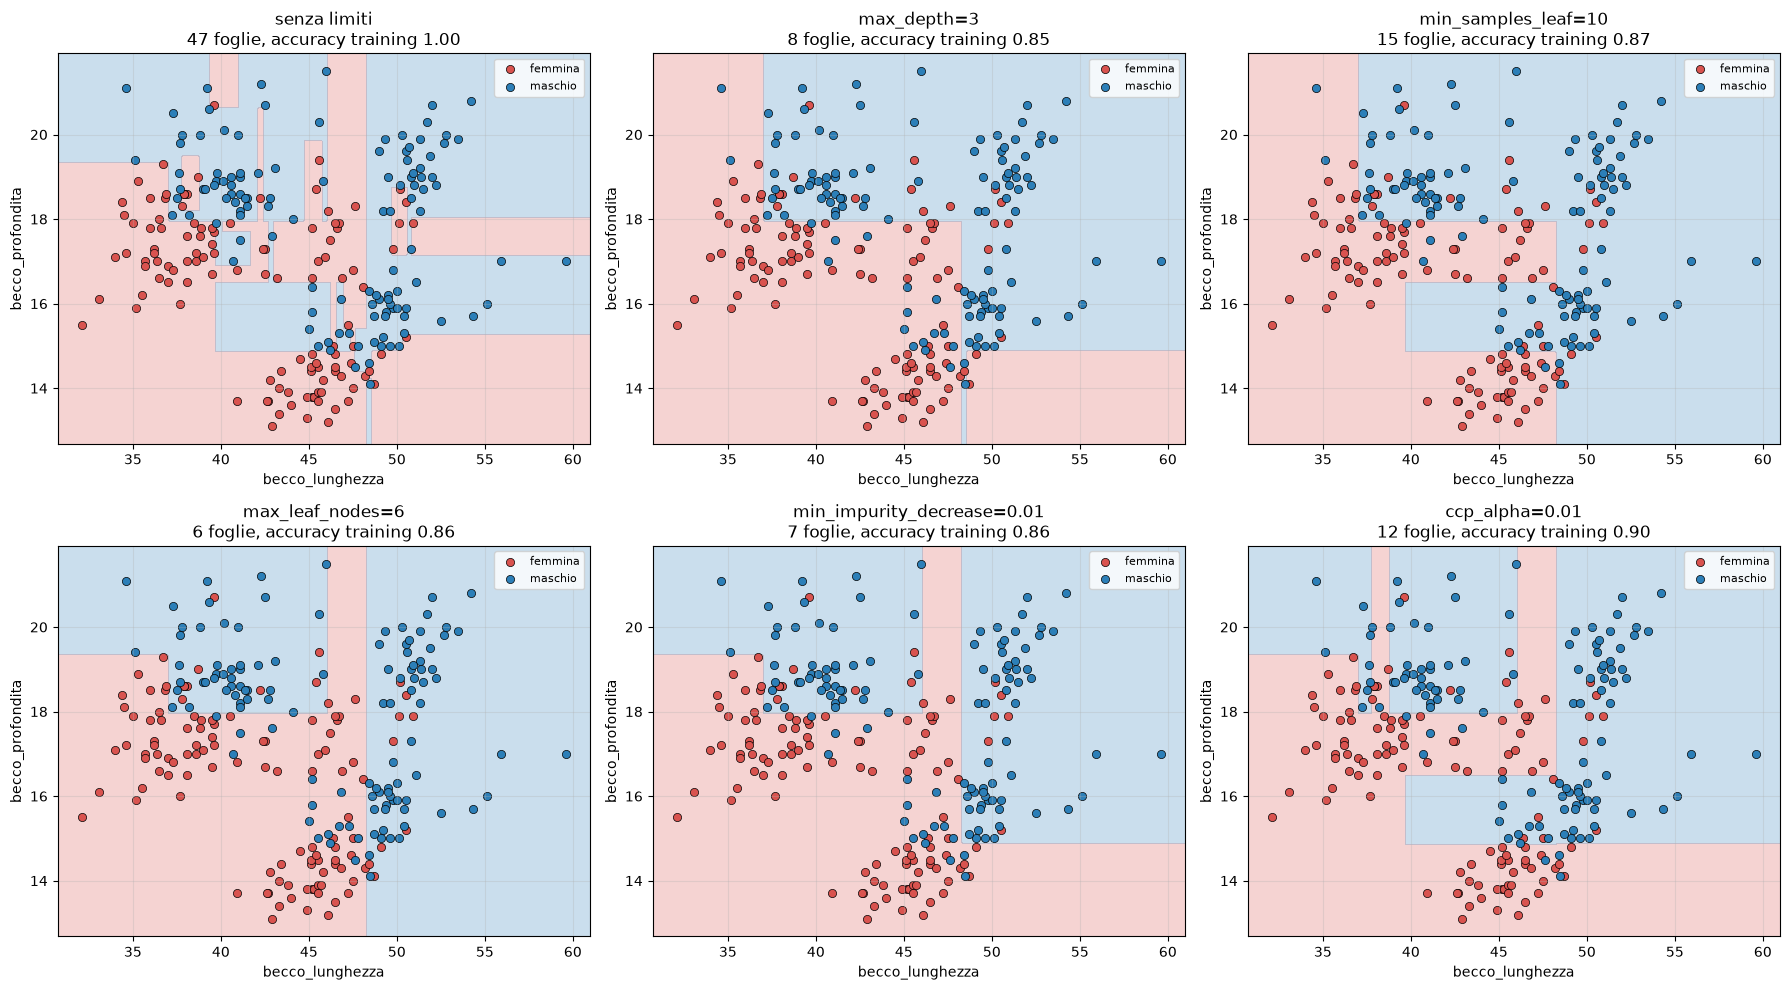

In [5]:
configurazioni = {                          # nome da mostrare → dizionario di iperparametri
    "senza limiti": {},
    "max_depth=3": {"max_depth": 3},
    "min_samples_leaf=10": {"min_samples_leaf": 10},
    "max_leaf_nodes=6": {"max_leaf_nodes": 6},
    "min_impurity_decrease=0.01": {"min_impurity_decrease": 0.01},
    "ccp_alpha=0.01": {"ccp_alpha": 0.01},
}

fig, assi = plt.subplots(2, 3, figsize=(18, 10))
# .ravel(): da matrice 2x3 a lista di 6 grafici; .items(): coppie (chiave, valore) del dizionario
for ax, (nome, parametri) in zip(assi.ravel(), configurazioni.items()):
    modello = DecisionTreeClassifier(random_state=0, **parametri).fit(X_train, y_train)
    acc = accuracy_score(y_train, modello.predict(X_train))
    disegna_frontiera(modello, X_train, y_train,
                      f"{nome}\n{modello.get_n_leaves()} foglie, accuracy training {acc:.2f}", ax=ax)
plt.tight_layout()
plt.show()

📌 Tutti fanno la stessa cosa in modi diversi: **meno foglie**, frontiera **più semplice**, accuracy di training **più bassa**. Quale sia il valore migliore non si vede da qui: lo decide la validazione (Parti 3 e 4).

### 2.2 Il pruning
Ci sono due strade per avere un albero più piccolo:
- **pre-pruning**: si **ferma la crescita** in anticipo (`max_depth`, `min_samples_leaf`, `max_leaf_nodes`, `min_impurity_decrease`);
- **post-pruning**: si fa crescere l'albero **completo** e poi si **potano** i rami che servono poco. In scikit-learn si regola con `ccp_alpha`.

**Che cosa fa `ccp_alpha`.** Pensalo come il **prezzo di ogni foglia**. Per ogni ramo dell'albero completo, scikit-learn guarda due cose:
- quanto quel ramo **abbassa l'impurità** sul training set (quanto rende le foglie più "pure", cioè con una sola classe);
- quante **foglie in più** costa rispetto a sostituirlo con una foglia sola.

Se il miglioramento per ogni foglia in più è **minore di `ccp_alpha`**, il ramo "è troppo costoso" e viene tagliato: al suo posto resta una foglia sola. Con `ccp_alpha = 0` le foglie non costano niente e l'albero resta completo; più `ccp_alpha` è grande, più rami vengono tagliati.

Quali valori provare? Non serve indovinarli: `cost_complexity_pruning_path` restituisce proprio i valori di `ccp_alpha` in cui un ramo diventa "troppo costoso", cioè quelli in cui l'albero potato **cambia**. Tra due valori consecutivi l'albero resta lo stesso.

Quanti valori di ccp_alpha: 25
I primi cinque: [0.     0.0029 0.0029 0.0032 0.0032]


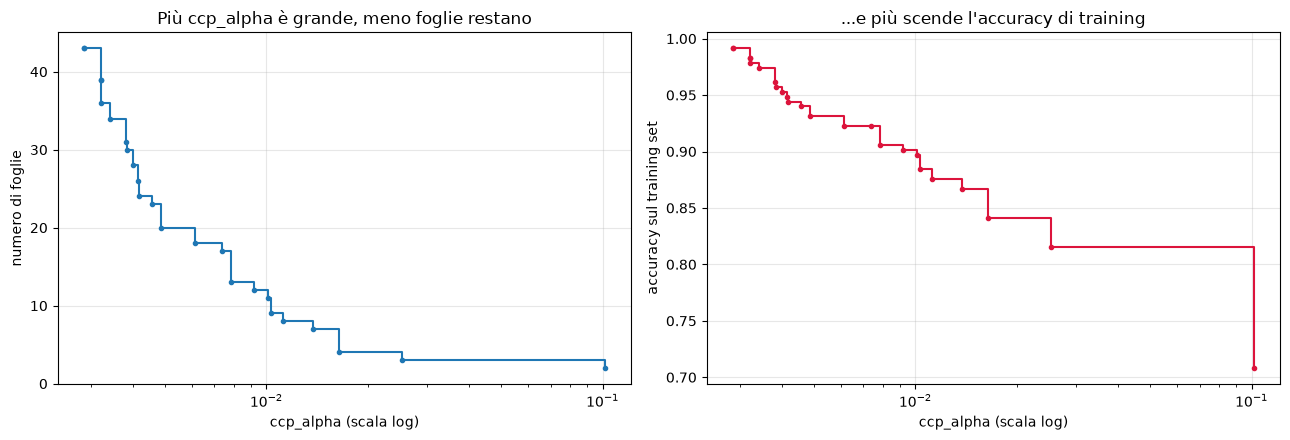

In [6]:
# calcola il "percorso di potatura" dell'albero completo sul training set
percorso = DecisionTreeClassifier(random_state=0).cost_complexity_pruning_path(X_train, y_train)
valori_alpha = percorso.ccp_alphas[:-1]   # l'ultimo valore pota tutto e lascia solo la radice: lo escludiamo

print("Quanti valori di ccp_alpha:", len(valori_alpha))
print("I primi cinque:", valori_alpha[:5].round(4))

foglie, acc_training = [], []
for a in valori_alpha:                    # per ogni alpha: addestro l'albero potato, conto le foglie e misuro il training
    potato = DecisionTreeClassifier(random_state=0, ccp_alpha=a).fit(X_train, y_train)
    foglie.append(potato.get_n_leaves())
    acc_training.append(accuracy_score(y_train, potato.predict(X_train)))

fig, assi = plt.subplots(1, 2, figsize=(13, 4.5))
# il primo alpha vale 0 e la scala log non lo può mostrare: partiamo dal secondo ([1:])
assi[0].step(valori_alpha[1:], foglie[1:], where="post", marker=".")
assi[0].set_ylabel("numero di foglie"); assi[0].set_title("Più ccp_alpha è grande, meno foglie restano")
assi[1].step(valori_alpha[1:], acc_training[1:], where="post", marker=".", color="crimson")
assi[1].set_ylabel("accuracy sul training set"); assi[1].set_title("...e più scende l'accuracy di training")
for ax in assi:
    ax.set_xscale("log"); ax.set_xlabel("ccp_alpha (scala log)"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Nei grafici ogni scalino è un taglio: l'albero perde foglie e un po' di accuracy di training, come con il pre-pruning. Quale `ccp_alpha` generalizza meglio non si vede da qui: questi valori saranno i candidati da provare con la cross-validation nell'esercizio della 4.6.

### 2.3 ⏩ Le formule del pruning
Come calcola scikit-learn i valori di `ccp_alpha`, e quando decide di tagliare un ramo? L'errore di un albero $T$ sul training set è l'impurità delle sue foglie, pesata per quanti pinguini contengono (la stessa media pesata dell'MSE pesato nella 2.8 dell'Esercitazione 2, con l'impurità di Gini, quella che l'albero usa di default):

$$R(T) = \sum_{\text{foglie } \ell} \frac{n_\ell}{n} \cdot \text{impurità}(\ell)$$

Il post-pruning cerca l'albero potato che rende più piccolo il **costo**, cioè l'errore più il prezzo delle foglie ($|T|$ è il numero di foglie):

$$R_\alpha(T) = R(T) + \alpha \cdot |T|$$

Prendiamo un nodo $t$ con sotto il suo ramo $T_t$:
- se **teniamo** il ramo, costa $R(T_t) + \alpha \cdot |T_t|$;
- se lo **tagliamo**, $t$ diventa una foglia sola e costa $R(t) + \alpha$, dove $R(t) = \frac{n_t}{n} \cdot \text{impurità}(t)$.

Tagliare conviene quando $R(t) + \alpha \leq R(T_t) + \alpha \cdot |T_t|$, cioè quando

$$\alpha \;\geq\; \alpha_{eff}(t) = \frac{R(t) - R(T_t)}{|T_t| - 1}$$

$\alpha_{eff}(t)$ è proprio il **miglioramento dell'errore per ogni foglia in più** del ramo. scikit-learn taglia il ramo con $\alpha_{eff}$ più piccolo (il "ramo più debole"), ricalcola gli $\alpha_{eff}$ sull'albero potato e ripete, finché tutti i rami rimasti hanno $\alpha_{eff} >$ `ccp_alpha`. I valori restituiti da `cost_complexity_pruning_path` sono gli $\alpha_{eff}$ dei rami tagliati uno dopo l'altro.

Verifichiamolo sull'albero completo: calcoliamo $\alpha_{eff}$ per ogni nodo interno e guardiamo il più piccolo.

> 🐍 `albero.tree_` contiene la struttura dell'albero, un array per ogni informazione, con una posizione per nodo: `children_left[i]` è il figlio sinistro del nodo `i` (vale `-1` se `i` è una foglia), `impurity[i]` la sua impurità, `n_node_samples[i]` i suoi pinguini. La funzione `ramo` chiama **se stessa** sui due figli (si dice *ricorsione*): così somma l'errore e conta le foglie di tutto il ramo, fino in fondo.

In [7]:
completo = DecisionTreeClassifier(random_state=0).fit(X_train, y_train)
struttura = completo.tree_
n = struttura.n_node_samples[0]                       # i pinguini della radice: tutto il training set

def R_nodo(i):
    """R(t): l'errore del nodo i se diventasse una foglia sola."""
    return struttura.n_node_samples[i] / n * struttura.impurity[i]

def ramo(i):
    """R(T_t) e numero di foglie del ramo che parte dal nodo i."""
    if struttura.children_left[i] == -1:              # una foglia: il ramo è lei stessa
        return R_nodo(i), 1
    R_sx, foglie_sx = ramo(struttura.children_left[i])     # il ramo sinistro
    R_dx, foglie_dx = ramo(struttura.children_right[i])    # il ramo destro
    return R_sx + R_dx, foglie_sx + foglie_dx

righe = []
for i in range(struttura.node_count):
    if struttura.children_left[i] != -1:              # solo i nodi interni si possono potare
        R_ramo, foglie_ramo = ramo(i)
        righe.append({"nodo": i, "pinguini": struttura.n_node_samples[i], "foglie del ramo": foglie_ramo,
                      "R(t)": R_nodo(i), "R(T_t)": R_ramo,
                      "alpha_eff": (R_nodo(i) - R_ramo) / (foglie_ramo - 1)})
tabella_alpha = pd.DataFrame(righe).sort_values("alpha_eff")

print(f"alpha_eff più piccolo:                      {tabella_alpha['alpha_eff'].iloc[0]:.5f}")
print(f"primo valore non nullo di ccp_alphas:       {percorso.ccp_alphas[1]:.5f}")
print("Foglie con ccp_alpha = quel valore:", DecisionTreeClassifier(random_state=0, ccp_alpha=percorso.ccp_alphas[1])
      .fit(X_train, y_train).get_n_leaves(), "invece di", completo.get_n_leaves())
tabella_alpha.head(4).round(5)

alpha_eff più piccolo:                      0.00286
primo valore non nullo di ccp_alphas:       0.00286
Foglie con ccp_alpha = quel valore: 43 invece di 47


,nodo,pinguini,foglie del ramo,R(t),R(T_t),alpha_eff
11,18,3,3,0.00572,0.0,0.00286
36,70,3,3,0.00572,0.0,0.00286
30,57,4,3,0.00644,0.0,0.00322
15,27,4,3,0.00644,0.0,0.00322


I due rami più deboli hanno lo stesso $\alpha_{eff}$ (0.00286): sono due nodi con 3 pinguini, divisi in 3 foglie pure. Le foglie pure hanno impurità 0, quindi $R(T_t) = 0$, e il miglioramento per foglia è minimo. Con `ccp_alpha` uguale a quel valore vengono tagliati entrambi: ognuno passa da 3 foglie a 1, e l'albero scende da 47 a 43 foglie.

---
# Parte 3 — Come scegliere: dalla validazione singola alla cross-validation

### 3.1 Un solo validation set
L'idea più semplice: dividere **di nuovo** il training set, in una parte per addestrare (75%) e una di **validazione** (25%) per confrontare gli alberi. Il test set resta chiuso.

Proviamo tutte le profondità da 1 a 12 con **sei divisioni diverse** dello stesso training set (cambia solo il `random_state` della divisione):

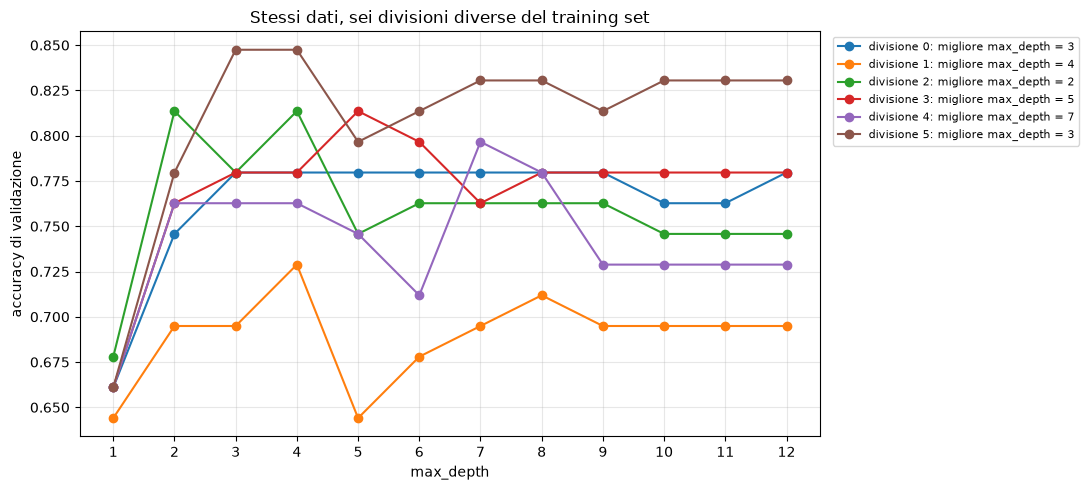

In [8]:
profondita = list(range(1, 13))

curve = []                                                # qui raccogliamo le sei curve
plt.figure(figsize=(11, 5))
for seme in range(6):
    # divido il TRAINING set in due: X_tr per addestrare, X_val per validare
    X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size=0.25,
                                                random_state=seme, stratify=y_train)
    acc_val = [accuracy_score(y_val, DecisionTreeClassifier(max_depth=d, random_state=0)
                                     .fit(X_tr, y_tr).predict(X_val))
               for d in profondita]                       # accuracy di validazione per ogni profondità
    curve.append(acc_val)
    migliore = profondita[int(np.argmax(acc_val))]        # la profondità con l'accuracy più alta
    plt.plot(profondita, acc_val, marker="o", label=f"divisione {seme}: migliore max_depth = {migliore}")

plt.xlabel("max_depth"); plt.ylabel("accuracy di validazione"); plt.xticks(profondita)
plt.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); plt.grid(alpha=0.3)   # legenda fuori dal grafico
plt.title("Stessi dati, sei divisioni diverse del training set")
plt.tight_layout()
plt.show()

📌 Cambia solo **quali** pinguini finiscono nel validation set, eppure la profondità "migliore" va da 2 a 7: con 59 pinguini di validazione, pochi pinguini in più o in meno classificati bene bastano a cambiare la scelta.

🤔 **Allora quale profondità scelgo?** Pensaci prima di eseguire la cella successiva.

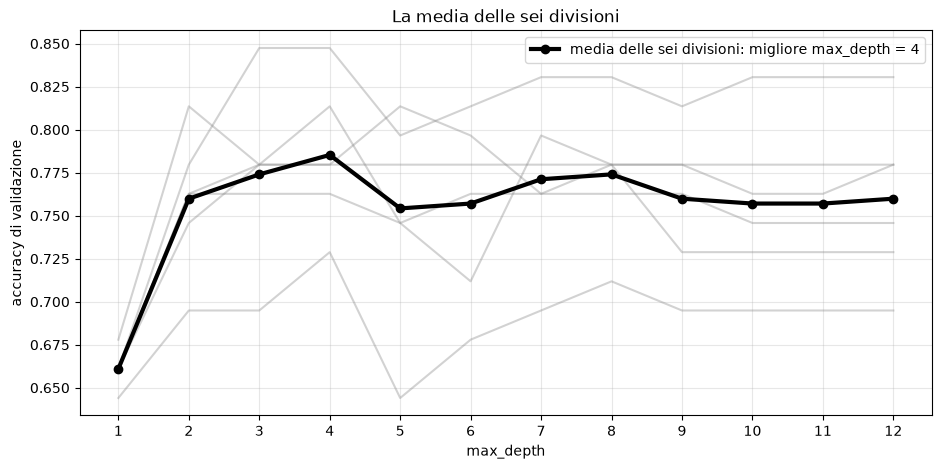

In [9]:
media = np.mean(curve, axis=0)                     # per ogni profondità, la media delle sei accuracy
migliore_media = profondita[int(np.argmax(media))]

plt.figure(figsize=(11, 5))
for acc_val in curve:
    plt.plot(profondita, acc_val, color="gray", alpha=0.35)          # le sei divisioni, in grigio
plt.plot(profondita, media, color="k", linewidth=3, marker="o",
         label=f"media delle sei divisioni: migliore max_depth = {migliore_media}")
plt.xlabel("max_depth"); plt.ylabel("accuracy di validazione"); plt.xticks(profondita)
plt.legend(); plt.grid(alpha=0.3); plt.title("La media delle sei divisioni")
plt.show()

Nessuna delle sei da sola: ognuna dipende da quali pinguini sono capitati nel validation set. Conviene **fare la media**: per ogni profondità, la media delle sei accuracy è una stima molto più stabile di una singola divisione. Qui la media premia `max_depth = 4`.

Le sei divisioni però sono estratte a caso, quindi si sovrappongono: alcuni pinguini sono finiti nel validation set più volte, altri mai. La **k-fold cross-validation** fa la stessa media in modo ordinato.

### 3.2 La k-fold cross-validation
La **k-fold cross-validation** divide il training set in $k$ parti (*fold*). A turno ogni fold fa da validation set e gli altri servono per addestrare: si ottengono $k$ punteggi, e se ne fa la media. Ogni pinguino del training set viene usato **una volta** per validare. Con $k = 5$:

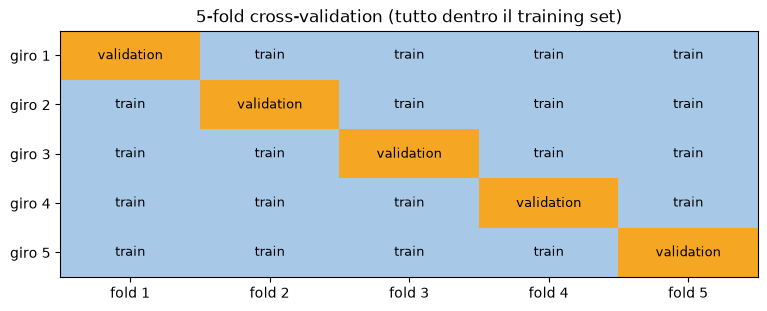

In [10]:
k = 5
schema = np.eye(k)                # matrice 5x5 con 1 sulla diagonale: il fold usato per la validazione

plt.figure(figsize=(9, 3.2))
plt.imshow(schema, aspect="auto", cmap=ListedColormap(["#A8C8E8", "#F5A623"]))   # 0 = azzurro, 1 = arancione
for i in range(k):
    for j in range(k):
        plt.text(j, i, "validation" if i == j else "train", ha="center", va="center", fontsize=9)
plt.xticks(range(k), [f"fold {j+1}" for j in range(k)])
plt.yticks(range(k), [f"giro {i+1}" for i in range(k)])
plt.title("5-fold cross-validation (tutto dentro il training set)")
plt.show()

In scikit-learn la divisione in fold la fa **`StratifiedKFold`**: *stratified* vuol dire che ogni fold ha la stessa proporzione di maschi e femmine del training set. **`cross_val_score`** fa da solo i $k$ addestramenti e restituisce i $k$ punteggi.

In [11]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 5 fold; shuffle=True mescola i pinguini prima di dividerli; random_state rende la divisione ripetibile
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

punteggi = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=0),   # il modello (non addestrato)
                           X_train, y_train,                                       # SOLO il training set
                           cv=cv)                                                  # come dividere
print("Che cosa restituisce:", type(punteggi))
print("Accuracy nei 5 fold:", punteggi.round(2))
print(f"Media: {punteggi.mean():.2f}  ± {punteggi.std():.2f} (deviazione standard)")

Che cosa restituisce: <class 'numpy.ndarray'>
Accuracy nei 5 fold: [0.83 0.77 0.74 0.83 0.83]
Media: 0.80  ± 0.04 (deviazione standard)


`cross_val_score` restituisce solo i punteggi di validazione. Se vogliamo anche l'accuracy di **training** di ogni giro (e i tempi), c'è **`cross_validate`**. In ognuno dei 5 giri:
1. addestra l'albero sui **4 fold di training** di quel giro;
2. `train_score`: l'accuracy sugli **stessi 4 fold** su cui ha appena imparato;
3. `test_score`: l'accuracy sul **fold di validazione** di quel giro, che l'albero non ha visto. Il nome è ingannevole: **non** è il nostro test set, che resta chiuso.

Restituisce un **dizionario** con un valore per giro.

> 🐍 Un **dizionario** associa delle **chiavi** a dei **valori**: `risultati["test_score"]` prende il valore della chiave `"test_score"`. `risultati.keys()` elenca le chiavi.

In [12]:
from sklearn.model_selection import cross_validate

risultati = cross_validate(DecisionTreeClassifier(random_state=0),   # l'albero senza limiti
                           X_train, y_train, cv=cv,
                           return_train_score=True)                  # calcola anche l'accuracy di training
print("Chiavi:", list(risultati.keys()))
print("train_score:", risultati["train_score"].round(2))    # accuracy sui 4 fold usati per addestrare
print("test_score: ", risultati["test_score"].round(2), " è il fold di validazione")     # accuracy sul fold di validazione
print(f"Media – training {risultati['train_score'].mean():.2f}, validazione {risultati['test_score'].mean():.2f}")

Chiavi: ['fit_time', 'score_time', 'test_score', 'train_score']
train_score: [1. 1. 1. 1. 1.]
test_score:  [0.87 0.64 0.79 0.8  0.78]  è il fold di validazione
Media – training 1.00, validazione 0.78


Training 1.00 in ogni giro e validazione molto più bassa: l'overfitting si vede senza toccare il test set.

### 3.3 ✏️ Esercizio: la curva della profondità
Per ogni profondità da 1 a 12 calcola l'**accuracy sul training set** (addestrando su tutto `X_train`) e l'**accuracy media in cross-validation** con la sua **deviazione standard**. Il grafico in fondo alla cella è già pronto: finché le liste sono vuote resta vuoto.

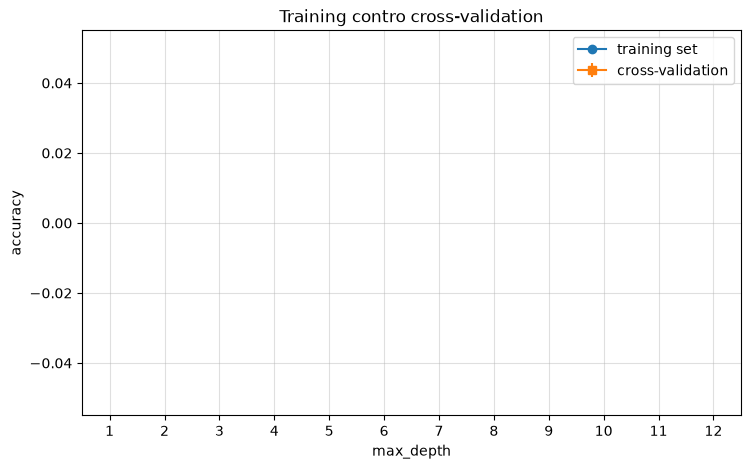

In [13]:
# ✏️ Esercizio
profondita = list(range(1, 13))
acc_train, acc_cv_media, acc_cv_std = [], [], []

for d in profondita:
    modello = DecisionTreeClassifier(max_depth=d, random_state=0)
    # ✏️ 1) addestra modello su X_train, y_train e aggiungi ad acc_train l'accuracy sul training set
    # ✏️ 2) calcola i punteggi di cross-validation con cross_val_score (usa cv=cv)
    # ✏️ 3) aggiungi media e deviazione standard dei punteggi ad acc_cv_media e acc_cv_std con .append()
    pass

n = len(acc_train)                       # quante profondità hai già calcolato
plt.figure(figsize=(8.5, 5))
plt.plot(profondita[:n], acc_train, marker="o", label="training set")
plt.errorbar(profondita[:n], acc_cv_media[:n], yerr=acc_cv_std[:n], marker="s", capsize=4, label="cross-validation")
plt.xlabel("max_depth"); plt.ylabel("accuracy"); plt.xticks(profondita); plt.xlim(0.5, 12.5)
plt.legend(); plt.grid(alpha=0.4); plt.title("Training contro cross-validation")
plt.show()

<details>
<summary><b>💡 Soluzione</b> (clicca per aprire, ma prima prova da solo!)</summary>

```python
for d in profondita:
    modello = DecisionTreeClassifier(max_depth=d, random_state=0)
    modello.fit(X_train, y_train)
    acc_train.append(accuracy_score(y_train, modello.predict(X_train)))
    punteggi = cross_val_score(modello, X_train, y_train, cv=cv)
    acc_cv_media.append(punteggi.mean())
    acc_cv_std.append(punteggi.std())

# il resto della cella (liste iniziali e grafico) resta com'è
```

</details>

📌 **Come si legge il grafico.** A sinistra l'albero è troppo semplice e sbaglia anche sul training (**underfitting**); a destra il training arriva a 1.00 mentre la cross-validation smette di salire (**overfitting**). Si sceglie la profondità con la cross-validation più alta, ricordando le barre: tra due profondità con punteggi entro le barre, conviene la più semplice.

Questo ciclo funziona, ma con due o più iperparametri insieme diventa un ciclo dentro un ciclo. scikit-learn lo fa per noi con **`GridSearchCV`**.

---
# Parte 4 — `GridSearchCV` passo per passo

`GridSearchCV` prova **tutte le combinazioni** di iperparametri che gli diamo, valuta ognuna con la cross-validation e tiene la migliore. Vediamolo un pezzo alla volta.

### 4.1 La griglia: iperparametro → valori da provare

In [14]:
from sklearn.model_selection import ParameterGrid

griglia_parametri = {                        # dizionario: nome dell'iperparametro → lista di valori
    "max_depth": list(range(1, 11)),         # 10 valori: 1, 2, ..., 10
    "min_samples_leaf": [1, 2, 5, 10, 20],   # 5 valori
}

combinazioni = list(ParameterGrid(griglia_parametri))   # tutte le combinazioni, una per riga
print("Le prime tre combinazioni:", combinazioni[:3])
print("Combinazioni:", len(combinazioni))
print("Fold:", cv.get_n_splits())
print("Addestramenti in cross-validation:", len(combinazioni) * cv.get_n_splits(), "(+ 1 finale, vedi 4.2)")

Le prime tre combinazioni: [{'max_depth': 1, 'min_samples_leaf': 1}, {'max_depth': 1, 'min_samples_leaf': 2}, {'max_depth': 1, 'min_samples_leaf': 5}]
Combinazioni: 50
Fold: 5
Addestramenti in cross-validation: 250 (+ 1 finale, vedi 4.2)


### 4.2 Creare la ricerca e addestrarla
`GridSearchCV` si usa come un modello: lo creo, poi chiamo `.fit()` **sul training set**.

In [15]:
from sklearn.model_selection import GridSearchCV

ricerca = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=0),   # il modello da mettere a punto
    param_grid=griglia_parametri,                       # le combinazioni da provare
    cv=cv,                                              # come fare la cross-validation (5 fold stratificati)
    scoring="accuracy",                                 # la misura con cui confrontarle
    return_train_score=True,                            # salva anche l'accuracy di training (serve in 4.3)
)                                                       # refit=True è il default: vedi sotto
ricerca.fit(X_train, y_train)                           # qui avvengono i 250 addestramenti

print("Iperparametri migliori (best_params_):", ricerca.best_params_)
print(f"Accuracy media in CV della migliore (best_score_): {ricerca.best_score_:.2f}")

Iperparametri migliori (best_params_): {'max_depth': 5, 'min_samples_leaf': 10}
Accuracy media in CV della migliore (best_score_): 0.82


Con `refit=True` (il default), dopo la ricerca `GridSearchCV` **riaddestra la combinazione migliore su tutto il training set**: il risultato è in `best_estimator_`, pronto per `.predict()`. Verifichiamolo addestrando a mano lo stesso albero:

In [16]:
albero_scelto = ricerca.best_estimator_          # l'albero migliore, già addestrato su tutto X_train

# lo stesso albero addestrato a mano su tutto il training set, con gli iperparametri migliori
a_mano = DecisionTreeClassifier(random_state=0, **ricerca.best_params_).fit(X_train, y_train)

print("Foglie dell'albero scelto:", albero_scelto.get_n_leaves())
print("Stesse predizioni dell'albero addestrato a mano?", (albero_scelto.predict(X_train) == a_mano.predict(X_train)).all())

Foglie dell'albero scelto: 13
Stesse predizioni dell'albero addestrato a mano? True


### 4.3 Tutti i risultati: `cv_results_`
`best_params_` dice solo chi ha vinto. Per vedere **tutte** le combinazioni c'è `cv_results_`: è un dizionario (una chiave per ogni informazione, un valore per ogni combinazione), che si trasforma facilmente in una tabella di pandas.

> 🐍 `pd.DataFrame(dizionario)` crea una tabella in cui ogni chiave diventa una colonna. `.sort_values("colonna")` ordina le righe; `tabella[[...]]` tiene solo alcune colonne.

In [17]:
risultati = pd.DataFrame(ricerca.cv_results_)
print("Colonne:", list(risultati.columns))

colonne_utili = ["params", "mean_test_score", "std_test_score", "rank_test_score", "mean_train_score"]
risultati[colonne_utili].sort_values("rank_test_score").head(8).round(3)

Colonne: ['mean_fit_time', 'std_fit_time', 'mean_score_time', 'std_score_time', 'param_max_depth', 'param_min_samples_leaf', 'params', 'split0_test_score', 'split1_test_score', 'split2_test_score', 'split3_test_score', 'split4_test_score', 'mean_test_score', 'std_test_score', 'rank_test_score', 'split0_train_score', 'split1_train_score', 'split2_train_score', 'split3_train_score', 'split4_train_score', 'mean_train_score', 'std_train_score']


,params,mean_test_score,std_test_score,rank_test_score,mean_train_score
23,"{'max_depth': 5, 'min_samples_leaf': 10}",0.824,0.037,1,0.853
28,"{'max_depth': 6, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
38,"{'max_depth': 8, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
33,"{'max_depth': 7, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
48,"{'max_depth': 10, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
43,"{'max_depth': 9, 'min_samples_leaf': 10}",0.820,0.040,2,0.859
20,"{'max_depth': 5, 'min_samples_leaf': 1}",0.815,0.052,7,0.913
21,"{'max_depth': 5, 'min_samples_leaf': 2}",0.811,0.067,8,0.906


`mean_test_score` e `std_test_score` sono media e deviazione standard sui fold di **validazione**, `rank_test_score` la classifica (a pari merito, stesso rango), `mean_train_score` l'accuracy sui fold di training (c'è solo con `return_train_score=True`).

🤔 Guarda le prime righe: quanto distano dalla migliore? Più della deviazione standard o meno?

### 4.4 La griglia come mappa di colori
Con due iperparametri possiamo disegnare `mean_test_score` come una **heatmap**: righe = `max_depth`, colonne = `min_samples_leaf`.

> 🐍 `tabella.pivot_table(index=..., columns=..., values=...)` riorganizza una tabella "lunga" (una riga per combinazione) in una tabella "larga" (una riga per ogni valore di `index`, una colonna per ogni valore di `columns`).

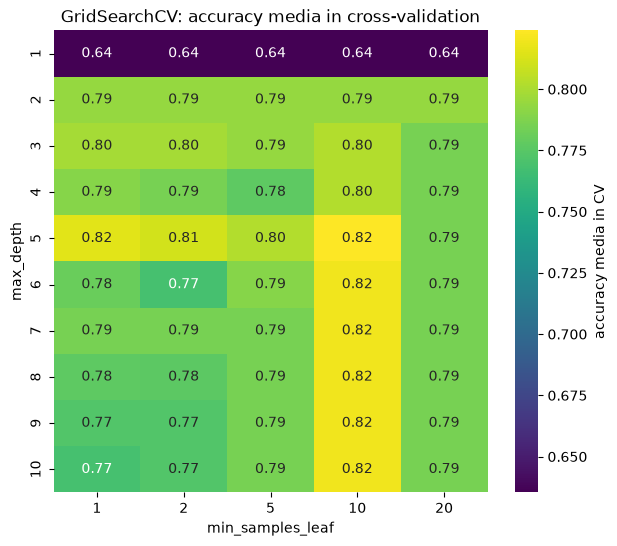

In [18]:
import seaborn as sns    # la stessa libreria del pairplot dell'Esercitazione 2

mappa = risultati.pivot_table(index="param_max_depth", columns="param_min_samples_leaf",
                              values="mean_test_score")
plt.figure(figsize=(7, 6))
sns.heatmap(mappa, annot=True, fmt=".2f", cmap="viridis", cbar_kws={"label": "accuracy media in CV"})
plt.xlabel("min_samples_leaf"); plt.ylabel("max_depth")
plt.title("GridSearchCV: accuracy media in cross-validation")
plt.show()

🤔 Con `min_samples_leaf=1` (nessun limite sulle foglie) l'accuracy scende quando l'albero diventa profondo. Con `min_samples_leaf` grande, invece, la profondità conta poco: perché?

### 4.5 Il parametro `scoring`
`scoring` decide **con quale misura** si confrontano le combinazioni. Proviamo `"f1_macro"` (la media dell'F1 delle due classi) al posto dell'accuracy:

In [19]:
ricerca_f1 = GridSearchCV(DecisionTreeClassifier(random_state=0), griglia_parametri,
                          cv=cv, scoring="f1_macro")     # cambia solo la misura
ricerca_f1.fit(X_train, y_train)

print("Con accuracy:", ricerca.best_params_, f"→ {ricerca.best_score_:.2f}")
print("Con f1_macro:", ricerca_f1.best_params_, f"→ {ricerca_f1.best_score_:.2f}")
print(y_train.value_counts())                            # quanti maschi e quante femmine nel training set

Con accuracy: {'max_depth': 5, 'min_samples_leaf': 10} → 0.82
Con f1_macro: {'max_depth': 5, 'min_samples_leaf': 10} → 0.82
sesso
maschio    118
femmina    115
Name: count, dtype: int64


Qui la scelta **non cambia**: maschi e femmine sono quasi lo stesso numero. Può cambiare con classi **sbilanciate**: l'accuracy resta alta anche indovinando quasi sempre la classe frequente, l'F1 macro no, perché pesa allo stesso modo anche la classe rara.

### 4.6 ✏️ Esercizio: il post-pruning nella griglia
Finora la griglia conteneva solo iperparametri di **pre-pruning**. Scrivi una griglia `griglia_ccp` che provi come `ccp_alpha` tutti i valori trovati con `cost_complexity_pruning_path` nella 2.2 (sono nella variabile `valori_alpha`). La cella poi confronta il risultato con quello della 4.2.

> 🐍 `valori_alpha.tolist()` trasforma l'array di NumPy in una lista Python, come quelle usate in `griglia_parametri`.

In [20]:
# ✏️ Esercizio: scrivi la griglia con ccp_alpha (con {} viene provato solo l'albero senza limiti)
griglia_ccp = {}

ricerca_ccp = GridSearchCV(DecisionTreeClassifier(random_state=0), griglia_ccp, cv=cv)
ricerca_ccp.fit(X_train, y_train)

print("Post-pruning:", ricerca_ccp.best_params_, f"→ CV {ricerca_ccp.best_score_:.2f},",
      ricerca_ccp.best_estimator_.get_n_leaves(), "foglie")
print("Pre-pruning: ", ricerca.best_params_, f"→ CV {ricerca.best_score_:.2f},",
      ricerca.best_estimator_.get_n_leaves(), "foglie")

Post-pruning: {} → CV 0.78, 47 foglie
Pre-pruning:  {'max_depth': 5, 'min_samples_leaf': 10} → CV 0.82, 13 foglie


<details>
<summary><b>💡 Soluzione</b> (clicca per aprire, ma prima prova da solo!)</summary>

```python
griglia_ccp = {"ccp_alpha": valori_alpha.tolist()}
```

</details>

<details>
<summary><b>🤔 Come si leggono i risultati</b> (apri dopo aver fatto l'esercizio)</summary>

Il post-pruning sceglie un albero con 7 foglie e CV 0.79, il pre-pruning 13 foglie e CV 0.82. La differenza è più piccola della deviazione standard tra i fold (0.04 nella 4.3): con questi dati i due modi di potare si equivalgono.

</details>

### 4.7 ⏩ Quando la griglia è troppo grande: `RandomizedSearchCV`
Gli addestramenti di una griglia sono il **prodotto** dei valori di ogni iperparametro per i fold: con tanti iperparametri diventano troppi. `RandomizedSearchCV` prova solo `n_iter` combinazioni **estratte a caso**, anche da **distribuzioni**: `randint(1, 21)` estrae un intero tra 1 e 20.

In [21]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint     # scipy: libreria scientifica, installata insieme a scikit-learn

distribuzioni = {
    "max_depth": randint(1, 21),          # interi da 1 a 20
    "min_samples_leaf": randint(1, 31),   # interi da 1 a 30
}
ricerca_casuale = RandomizedSearchCV(DecisionTreeClassifier(random_state=0), distribuzioni,
                                     n_iter=20,          # solo 20 combinazioni sulle 600 possibili
                                     cv=cv, random_state=0)
ricerca_casuale.fit(X_train, y_train)

print("Addestramenti in CV:", 20 * cv.get_n_splits(), "invece di", 20 * 30 * cv.get_n_splits())
print("Migliore:", ricerca_casuale.best_params_, f"→ CV {ricerca_casuale.best_score_:.2f}")

Addestramenti in CV: 100 invece di 3000
Migliore: {'max_depth': 14, 'min_samples_leaf': 9} → CV 0.81


### 4.8 🔓 Valutazione finale e stima del sesso
Abbiamo scelto l'albero **senza mai guardare il test set**. Ora lo apriamo, una volta sola, per confrontare l'albero senza limiti con quello scelto da `GridSearchCV`.

Test – albero senza limiti:      0.77
Test – albero scelto (GridSearch): 0.84


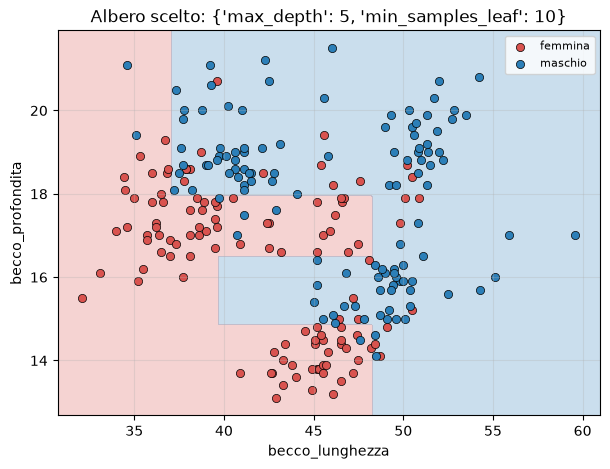

In [22]:
print(f"Test – albero senza limiti:      {accuracy_score(y_test, albero_libero.predict(X_test)):.2f}")
print(f"Test – albero scelto (GridSearch): {accuracy_score(y_test, albero_scelto.predict(X_test)):.2f}")
disegna_frontiera(albero_scelto, X_train, y_train, f"Albero scelto: {ricerca.best_params_}")

L'albero scelto passa da 0.77 a 0.84 sul test set, e la sua frontiera non ha più isolette. Usiamolo per stimare il sesso dei 9 pinguini a cui manca:

In [23]:
stime = sesso_mancante[["specie", "becco_lunghezza", "becco_profondita"]].copy()   # .copy(): una tabella nuova
stime["albero (becco)"] = albero_scelto.predict(sesso_mancante[["becco_lunghezza", "becco_profondita"]])
stime

,specie,becco_lunghezza,becco_profondita,albero (becco)
8,Adelie,34.1,18.1,femmina
9,Adelie,42.0,20.2,maschio
10,Adelie,37.8,17.1,femmina
11,Adelie,37.8,17.3,femmina
47,Adelie,37.5,18.9,maschio
246,Gentoo,44.5,14.3,femmina
286,Gentoo,46.2,14.4,femmina
324,Gentoo,47.3,13.8,femmina
336,Gentoo,44.5,15.7,maschio


---
# Parte 5 — La varianza: perché un albero solo non basta

### 5.1 Stesso algoritmo, dati quasi uguali
Creiamo 4 **campioni bootstrap** del training set: estrazioni **con reinserimento** della stessa dimensione dell'originale (alcuni pinguini compaiono più volte, altri mai). Su ognuno addestriamo un albero senza limiti.

> 🐍 `rng = np.random.default_rng(0)` crea un generatore di numeri casuali con seme fisso. `rng.choice(n, size=n, replace=True)` estrae `n` numeri tra 0 e `n-1` **con reinserimento**. `.iloc[indici]` prende le righe in quelle posizioni. `enumerate(...)` dà anche il numero del giro: 0, 1, 2, 3.

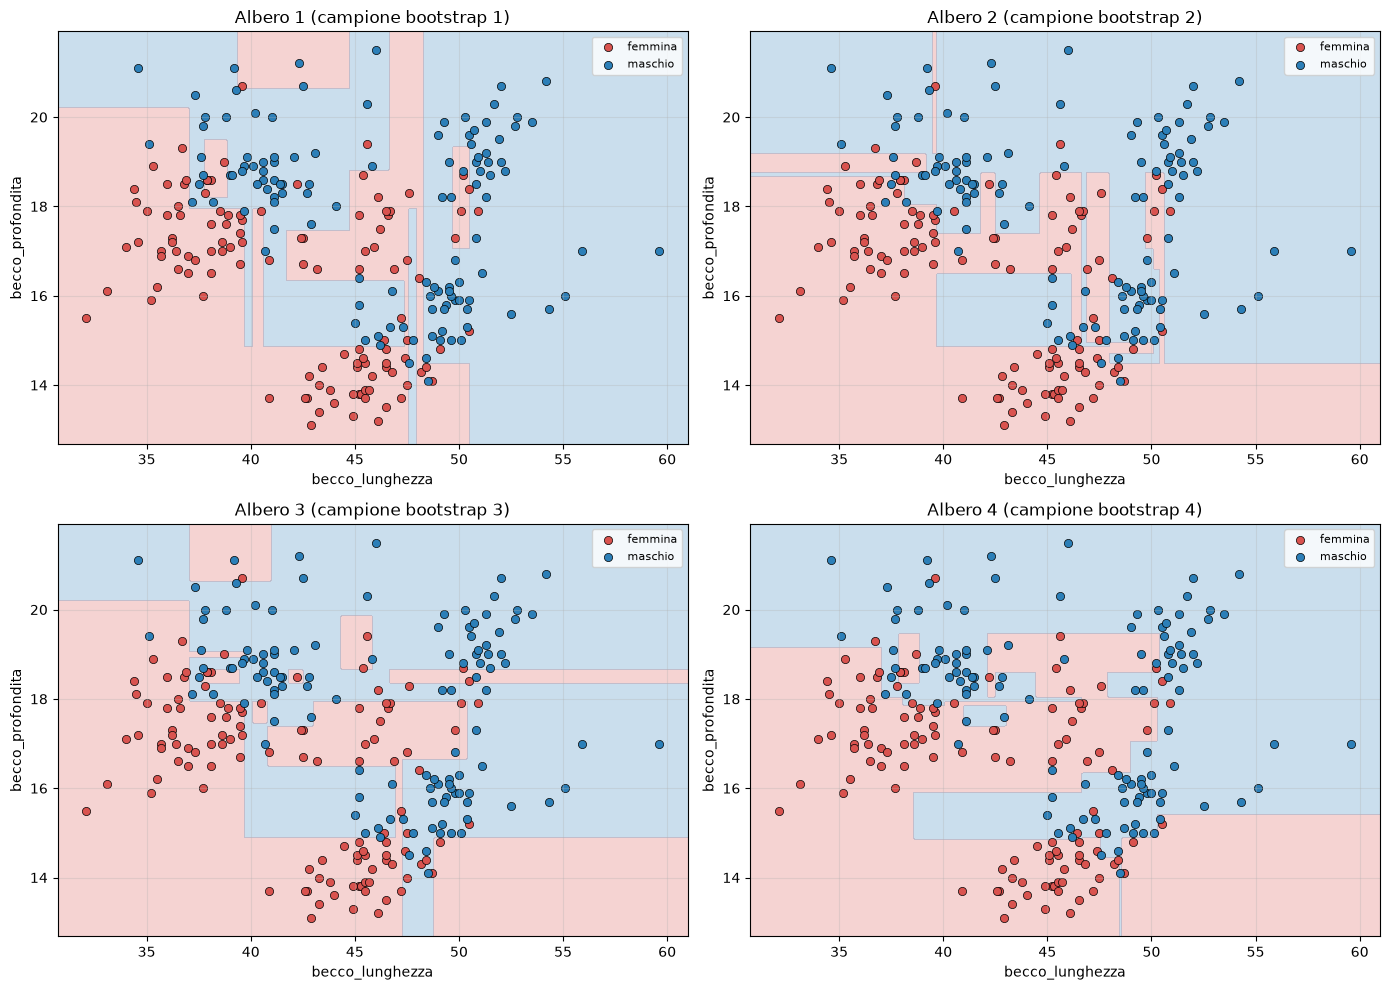

In [24]:
rng = np.random.default_rng(0)
n = len(X_train)

fig, assi = plt.subplots(2, 2, figsize=(14, 10))
for i, ax in enumerate(assi.ravel()):
    indici = rng.choice(n, size=n, replace=True)                    # un campione bootstrap
    X_boot, y_boot = X_train.iloc[indici], y_train.iloc[indici]
    albero_boot = DecisionTreeClassifier(random_state=0).fit(X_boot, y_boot)
    disegna_frontiera(albero_boot, X_train, y_train, f"Albero {i + 1} (campione bootstrap {i + 1})", ax=ax)
plt.tight_layout()
plt.show()

Le quattro frontiere sono molto diverse, anche se i dati sono quasi gli stessi: un albero profondo ha **alta varianza**.

### 5.2 Anche la scelta degli iperparametri è instabile
La stessa instabilità si vede nella ricerca degli iperparametri. Ripetiamo la `GridSearchCV` della Parte 4 cambiando solo il `random_state` della cross-validation, cioè come vengono formati i fold:

In [25]:
righe = []
for seme in range(5):
    cv_seme = StratifiedKFold(n_splits=5, shuffle=True, random_state=seme)   # fold diversi
    ricerca_seme = GridSearchCV(DecisionTreeClassifier(random_state=0), griglia_parametri, cv=cv_seme)
    ricerca_seme.fit(X_train, y_train)
    righe.append({"random_state della CV": seme, **ricerca_seme.best_params_,      # ** anche dentro un dizionario
                  "accuracy CV": ricerca_seme.best_score_})
pd.DataFrame(righe).round(2)

,random_state della CV,max_depth,min_samples_leaf,accuracy CV
0,0,5,10,0.82
1,1,6,1,0.82
2,2,3,2,0.81
3,3,4,1,0.80
4,4,10,1,0.80


Con fold diversi `GridSearchCV` sceglie alberi diversi, con punteggi tra 0.80 e 0.82: molte combinazioni sono quasi alla pari, e piccole differenze nei fold bastano a cambiare la vincitrice.

📌 Un singolo albero dipende molto dai dati su cui è addestrato. L'idea degli **ensemble** è sfruttare proprio questo: addestrare **tanti** alberi su campioni diversi e **mediare** le loro risposte (per la classificazione: farli votare). Gli errori dei singoli alberi, se sono diversi tra loro, in parte si compensano.

---
# Parte 6 — Ensemble

### 6.1 Il bootstrap da vicino
Quanti pinguini **diversi** finiscono in un campione bootstrap? Ripetiamo l'estrazione 1000 volte.

In [26]:
# per 1000 volte: estraggo un campione bootstrap e calcolo la frazione di pinguini diversi
frazioni = [len(np.unique(rng.choice(n, size=n, replace=True))) / n for _ in range(1000)]   # _ = variabile che non usiamo
print(f"Pinguini diversi in un campione, in media: {np.mean(frazioni):.1%}  (1 - 1/e = {1 - 1/np.e:.1%})")

Pinguini diversi in un campione, in media: 63.3%  (1 - 1/e = 63.2%)


In ogni campione c'è circa il **63%** dei pinguini; il restante **37%**, mai visto da quell'albero, sono gli esempi **out-of-bag** (OOB): servono a stimare la generalizzazione **senza cross-validation e senza test set**.

### 6.2 Random forest
Una **random forest** addestra tanti alberi profondi, ognuno su un campione bootstrap, e li fa votare. In più, a ogni nodo ogni albero può scegliere solo tra **alcune feature estratte a caso** (`max_features`), così gli alberi si somigliano meno. Con `oob_score=True` calcola anche la stima out-of-bag.

Random forest – stima out-of-bag (oob_score_): 0.81


Random forest – cross-validation:              0.80
Albero senza limiti – cross-validation:        0.78
Albero scelto con GridSearchCV – CV:           0.82


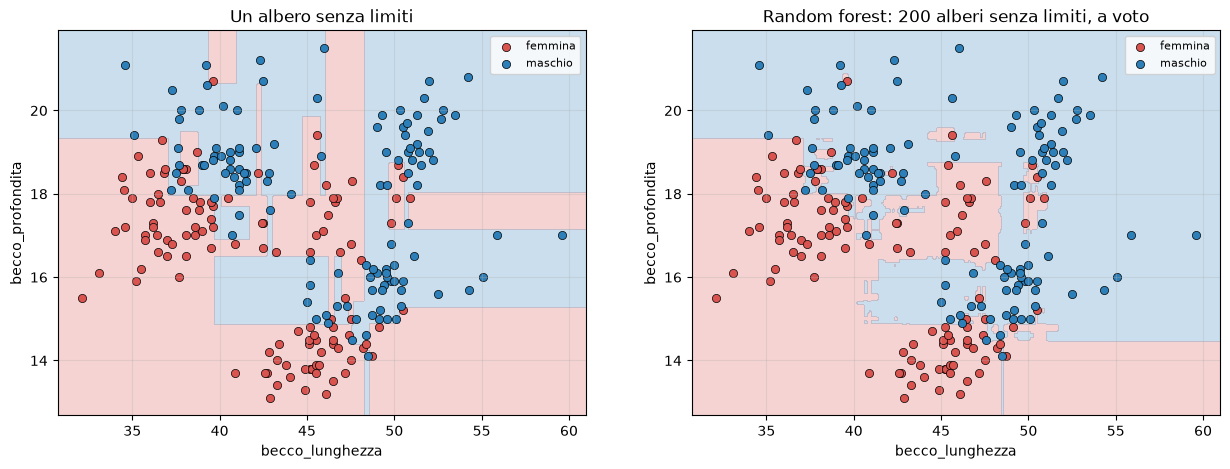

In [27]:
from sklearn.ensemble import RandomForestClassifier

foresta = RandomForestClassifier(n_estimators=200,      # 200 alberi
                                 oob_score=True,        # calcola la stima out-of-bag
                                 random_state=0)
foresta.fit(X_train, y_train)

print(f"Random forest – stima out-of-bag (oob_score_): {foresta.oob_score_:.2f}")
print(f"Random forest – cross-validation:              {cross_val_score(foresta, X_train, y_train, cv=cv).mean():.2f}")
print(f"Albero senza limiti – cross-validation:        {cross_val_score(albero_libero, X_train, y_train, cv=cv).mean():.2f}")
print(f"Albero scelto con GridSearchCV – CV:           {ricerca.best_score_:.2f}")

fig, assi = plt.subplots(1, 2, figsize=(15, 5))
disegna_frontiera(albero_libero, X_train, y_train, "Un albero senza limiti", ax=assi[0])
disegna_frontiera(foresta, X_train, y_train, "Random forest: 200 alberi senza limiti, a voto", ax=assi[1])
plt.show()

📌 La stima out-of-bag (0.81) è vicina alla cross-validation (0.80), con un solo addestramento invece di cinque. Gli alberi senza limiti da soli arrivano a 0.78; votando, senza nessuna messa a punto, salgono a 0.80. L'albero scelto con `GridSearchCV` (0.82) resta un po' meglio: con due sole feature la foresta ha poco da aggiungere, e 200 alberi non si leggono come un `if`/`else`.

### 6.3 ✏️ Esercizio: quanti alberi servono?
Calcola l'accuracy media in cross-validation di una random forest con un numero crescente di alberi (`n_estimators`). Il grafico è già pronto.

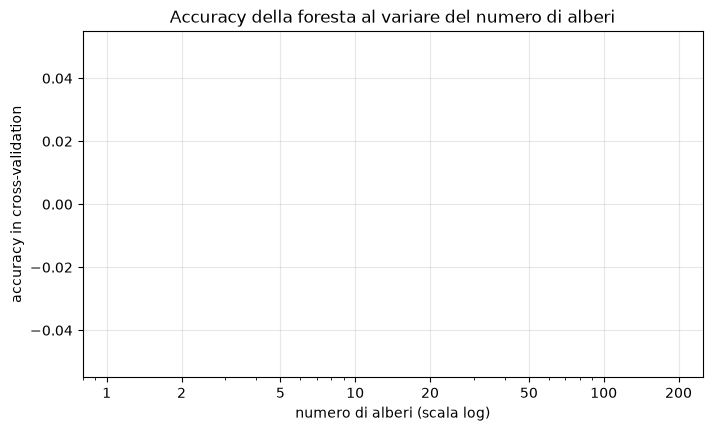

In [28]:
# ✏️ Esercizio
numero_alberi = [1, 2, 5, 10, 20, 50, 100, 200]
acc_foresta = []

for b in numero_alberi:
    # ✏️ crea una RandomForestClassifier con n_estimators=b e random_state=0,
    #    calcola l'accuracy media in cross-validation (cv=cv) e aggiungila ad acc_foresta
    pass

plt.figure(figsize=(8, 4.5))
plt.plot(numero_alberi[:len(acc_foresta)], acc_foresta, marker="o")
plt.xscale("log"); plt.xticks(numero_alberi, numero_alberi); plt.xlim(0.8, 250)
plt.xlabel("numero di alberi (scala log)"); plt.ylabel("accuracy in cross-validation"); plt.grid(alpha=0.3)
plt.title("Accuracy della foresta al variare del numero di alberi")
plt.show()

<details>
<summary><b>💡 Soluzione</b> (clicca per aprire, ma prima prova da solo!)</summary>

```python
for b in numero_alberi:
    foresta_b = RandomForestClassifier(n_estimators=b, random_state=0)
    acc_foresta.append(cross_val_score(foresta_b, X_train, y_train, cv=cv).mean())

# il resto della cella (liste iniziali e grafico) resta com'è
```

</details>

<details>
<summary><b>🤔 Come si legge il grafico</b> (apri dopo aver fatto l'esercizio)</summary>

Con 1 o 2 alberi l'accuracy è circa 0.76, come un albero solo; con 5 sale a 0.81, poi resta tra 0.79 e 0.81: le oscillazioni sono rumore della stima. Più alberi non fanno peggiorare la foresta, ma dopo poche decine non la migliorano più e costano solo tempo.

</details>

### 6.4 Tutte le misure, e la ricerca degli iperparametri sulla foresta
Finora abbiamo usato solo il becco, per poter disegnare la frontiera. Ora usiamo tutte e quattro le misure, **con la stessa divisione** train/test, e cerchiamo gli iperparametri **con lo stesso codice della Parte 4**: cambiano solo il modello e la griglia. Per la foresta proviamo `max_features` (quante feature estratte a caso a ogni nodo) e `min_samples_leaf`; `n_jobs=-1` usa tutti i processori, per fare prima.

> 🐍 `df.loc[indici, colonne]` seleziona righe per **etichetta** (l'indice a sinistra della tabella) e colonne per nome. Con gli indici di `X_train` e `X_test` teniamo gli stessi pinguini di prima.

In [29]:
misure = ["becco_lunghezza", "becco_profondita", "pinna", "peso"]
X4_train = df.loc[X_train.index, misure]     # stessi pinguini di X_train, con 4 colonne
X4_test = df.loc[X_test.index, misure]       # stessi pinguini di X_test (resta chiuso 🔒)

# stesso codice della Parte 4: cambiano solo il modello e la griglia
ricerca_albero4 = GridSearchCV(DecisionTreeClassifier(random_state=0), griglia_parametri, cv=cv)
ricerca_albero4.fit(X4_train, y_train)

griglia_foresta = {
    "max_features": [1, 2, 3, 4],          # 4 = tutte le feature: nessuna estrazione a caso
    "min_samples_leaf": [1, 2, 5, 10],
}
ricerca_foresta = GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=0),
                               griglia_foresta, cv=cv, n_jobs=-1)
ricerca_foresta.fit(X4_train, y_train)

print("Albero: ", ricerca_albero4.best_params_, f"→ CV {ricerca_albero4.best_score_:.2f}")
print("Foresta:", ricerca_foresta.best_params_, f"→ CV {ricerca_foresta.best_score_:.2f}")
pd.DataFrame(ricerca_foresta.cv_results_).pivot_table(index="param_max_features", columns="param_min_samples_leaf",
                                                      values="mean_test_score").round(2)

Albero:  {'max_depth': 5, 'min_samples_leaf': 2} → CV 0.89
Foresta: {'max_features': 4, 'min_samples_leaf': 1} → CV 0.89


param_min_samples_leaf,1,2,5,10
param_max_features,,,,
1,0.89,0.89,0.88,0.88
2,0.89,0.88,0.88,0.87
3,0.89,0.88,0.89,0.87
4,0.89,0.89,0.88,0.88


Con le quattro misure l'accuracy in CV sale da 0.82 a 0.89, sia per l'albero sia per la foresta; nella tabella della foresta tutte le combinazioni stanno tra 0.87 e 0.89. La foresta dice anche **quanto ha contato ogni misura** (`feature_importances_`: quanto le domande su quella feature hanno ridotto l'impurità, in media sui 200 alberi; la somma fa 1).

pinna               0.06
becco_lunghezza     0.16
peso                0.38
becco_profondita    0.40
dtype: float64


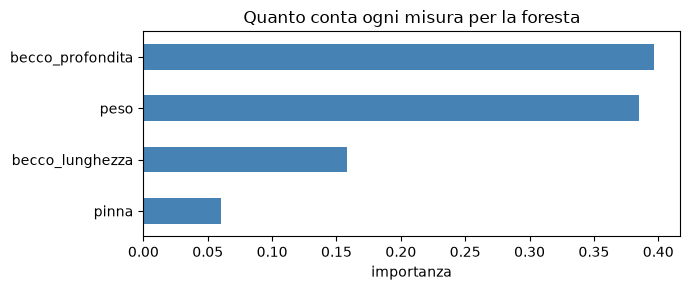

In [30]:
foresta4 = ricerca_foresta.best_estimator_
importanze = pd.Series(foresta4.feature_importances_, index=misure).sort_values()   # una Series: valori con etichette
print(importanze.round(2))
importanze.plot.barh(figsize=(7, 3), color="steelblue")
plt.xlabel("importanza"); plt.title("Quanto conta ogni misura per la foresta")
plt.tight_layout()
plt.show()

🤔 Le più importanti sono la profondità del becco e il peso. Perché il peso aiuta tanto a distinguere maschi e femmine?

### 6.5 ⏩ Gradient boosting
Il **boosting** addestra in **sequenza** alberi poco profondi, ognuno dei quali corregge gli errori dei precedenti. `n_estimators` (quanti alberi) e `learning_rate` (quanto conta ogni albero) vanno scelti insieme, con lo stesso codice della Parte 4:

Boosting: {'learning_rate': 0.01, 'n_estimators': 100} → CV 0.91


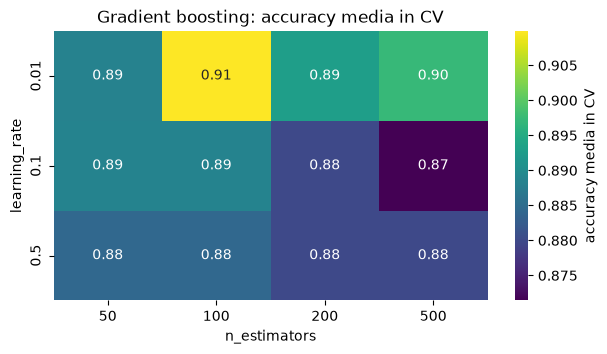

In [31]:
from sklearn.ensemble import GradientBoostingClassifier

griglia_boosting = {
    "learning_rate": [0.01, 0.1, 0.5],
    "n_estimators": [50, 100, 200, 500],
}
ricerca_boosting = GridSearchCV(GradientBoostingClassifier(random_state=0), griglia_boosting, cv=cv, n_jobs=-1)
ricerca_boosting.fit(X4_train, y_train)

print("Boosting:", ricerca_boosting.best_params_, f"→ CV {ricerca_boosting.best_score_:.2f}")
mappa_boosting = pd.DataFrame(ricerca_boosting.cv_results_).pivot_table(
    index="param_learning_rate", columns="param_n_estimators", values="mean_test_score")
plt.figure(figsize=(7, 3.5))
sns.heatmap(mappa_boosting, annot=True, fmt=".2f", cmap="viridis", cbar_kws={"label": "accuracy media in CV"})
plt.xlabel("n_estimators"); plt.ylabel("learning_rate"); plt.title("Gradient boosting: accuracy media in CV")
plt.show()

Le differenze sono piccole (da 0.87 a 0.91), ma con `learning_rate=0.1` l'accuracy scende leggermente passando da 100 a 500 alberi: a differenza della foresta, il boosting con troppi alberi può andare in overfitting. Invece di provare tanti `n_estimators` si usa l'**early stopping**: si mette da parte una frazione del training (`validation_fraction`) e ci si ferma quando per `n_iter_no_change` alberi di fila il punteggio lì non migliora.

In [32]:
boosting_es = GradientBoostingClassifier(n_estimators=1000,         # al massimo 1000 alberi
                                         learning_rate=0.1,
                                         validation_fraction=0.2,   # il 20% del training per decidere quando fermarsi
                                         n_iter_no_change=10,       # stop dopo 10 alberi senza miglioramenti
                                         random_state=0)
boosting_es.fit(X4_train, y_train)
print("Alberi usati davvero (n_estimators_):", boosting_es.n_estimators_, "su 1000")
print(f"Accuracy in CV: {cross_val_score(boosting_es, X4_train, y_train, cv=cv).mean():.2f}")

Alberi usati davvero (n_estimators_): 49 su 1000
Accuracy in CV: 0.88


### 6.6 🔓 Il confronto finale
I tre modelli scelti con `GridSearchCV` sulle quattro misure, con la deviazione standard della combinazione migliore (`best_index_` è la sua riga in `cv_results_`):

In [33]:
ricerche = {"albero": ricerca_albero4, "random forest": ricerca_foresta, "gradient boosting": ricerca_boosting}

righe = []
for nome, r in ricerche.items():
    righe.append({"modello": nome,
                  "iperparametri": r.best_params_,
                  "accuracy CV media": r.best_score_,
                  "deviazione std": r.cv_results_["std_test_score"][r.best_index_]})
confronto = pd.DataFrame(righe).sort_values("accuracy CV media", ascending=False)
confronto.round(2)

,modello,iperparametri,accuracy CV media,deviazione std
2,gradient boosting,"{'learning_rate': 0.01, 'n_estimators': 100}",0.91,0.02
0,albero,"{'max_depth': 5, 'min_samples_leaf': 2}",0.89,0.02
1,random forest,"{'max_features': 4, 'min_samples_leaf': 1}",0.89,0.01


I tre modelli sono **alla pari**: tra il primo e l'ultimo c'è 0.02, circa la deviazione standard tra i fold. Il salto vero è venuto dall'**aggiungere informazione** (da 0.82 a 0.89), non dal cambiare modello. Scegliamo come sempre la CV più alta e valutiamo sul test set solo quel modello.

📌 In un progetto vero il test set si apre **una volta sola** in tutto. Qui lo riapriamo perché la Parte 6 è un secondo esperimento con più feature, ma la scelta è fatta solo con la cross-validation.

In [34]:
nome_scelto = confronto["modello"].iloc[0]                 # la prima riga: CV più alta
modello_scelto = ricerche[nome_scelto].best_estimator_    # già riaddestrato su tutto il training set
print(f"Modello scelto: {nome_scelto}")
print(f"Accuracy sul test set: {accuracy_score(y_test, modello_scelto.predict(X4_test)):.2f}")

stime[f"{nome_scelto} (4 misure)"] = modello_scelto.predict(sesso_mancante[misure])
stime

Modello scelto: gradient boosting
Accuracy sul test set: 0.87


,specie,becco_lunghezza,becco_profondita,albero (becco),gradient boosting (4 misure)
8,Adelie,34.1,18.1,femmina,femmina
9,Adelie,42.0,20.2,maschio,maschio
10,Adelie,37.8,17.1,femmina,femmina
11,Adelie,37.8,17.3,femmina,femmina
47,Adelie,37.5,18.9,maschio,maschio
246,Gentoo,44.5,14.3,femmina,femmina
286,Gentoo,46.2,14.4,femmina,femmina
324,Gentoo,47.3,13.8,femmina,femmina
336,Gentoo,44.5,15.7,maschio,maschio


Sul test set il gradient boosting fa 0.87, meno dello 0.91 in CV: con 100 pinguini di test, 4 errori in più spostano l'accuracy di 0.04. Anche il test set è una stima rumorosa: differenze di 0.01 o 0.02 tra modelli non vanno prese sul serio.

🤔 Le stime sui 9 pinguini sono uguali a quelle dell'albero della Parte 4, che usava solo il becco. Ti aspettavi che cambiassero? A quale delle due stime daresti più fiducia, e perché?

---
# Riepilogo

| Concetto | Dove l'abbiamo visto | In scikit-learn |
|---|---|---|
| Iperparametri che fermano la crescita (pre-pruning) | 2.1 | `max_depth`, `min_samples_leaf`, `max_leaf_nodes`, `min_impurity_decrease` |
| Post-pruning | 2.2, 2.3 ⏩, 4.6 | `ccp_alpha`, `cost_complexity_pruning_path` |
| Un solo validation set è instabile | 3.1 | `train_test_split` sul training set |
| k-fold cross-validation | 3.2, 3.3 | `StratifiedKFold`, `cross_val_score`, `cross_validate` |
| Ricerca degli iperparametri | 4.1–4.5 | `GridSearchCV`: `param_grid`, `best_params_`, `best_score_`, `best_estimator_`, `cv_results_`, `scoring` |
| Ricerca casuale | 4.7 | `RandomizedSearchCV` |
| Test set usato una volta sola | 4.8, 6.6 | 🔒 / 🔓 |
| Varianza di un albero | 5.1, 5.2 | campioni bootstrap |
| Bootstrap e out-of-bag | 6.1, 6.2 | `oob_score=True`, `oob_score_` |
| Random forest | 6.2–6.4 | `RandomForestClassifier`, `n_estimators`, `max_features`, `feature_importances_` |
| Boosting ed early stopping | 6.5 | `GradientBoostingClassifier`, `learning_rate`, `n_iter_no_change`, `validation_fraction` |

### 🏠 Per casa (facoltativo)
1. Nella 6.4 sostituisci `GridSearchCV` con `RandomizedSearchCV` sulla foresta e aggiungi `n_estimators` e `max_depth` alle distribuzioni. Trovi qualcosa di meglio di 0.89?
2. Ripeti la Parte 4 con un altro target: la **specie** (tre classi), con le due misure del becco. Usa `scoring="f1_macro"`: la scelta cambia rispetto a `"accuracy"`? Le tre specie hanno lo stesso numero di pinguini?
3. Usa `GridSearchCV` con un `RandomForestRegressor` per stimare il **peso** (Esercitazione 2) dalle altre tre misure (`becco_lunghezza`, `becco_profondita`, `pinna`). Serve `scoring="neg_mean_squared_error"`: scikit-learn cerca sempre il punteggio **più alto**, quindi l'MSE va cambiato di segno. Batte la regressione lineare?